# Block Y1B: Creative Brief Template

Please, use this template to write down your solutions to the DataLab Tasks. If you have any questions, please, contact your mentor or the content responsible. 

## Important Notes:
- [ ] Please, rename the file to ```CreativeBrief_<your_name>_<studentnumber>.ipynb``` before submitting it. 
- [ ] Upload this template to the 'Deliverables' folder in your BUas GitHub repository.
- [ ] You are allowed to add as many (Markdown/Python) cells as you need. 
- [ ] If the task requires you to only write code or text, please, delete the unnecessary cell.
- [ ] Your work should be reproducible, meaning that we should be able to run your code in the template and get the same results as you did. Tip: use relative paths to load your data!
- [ ] Ensure that before you hand in the template, you press ```Restart & Run all```; we should be able to see the results of your code in the notebook (i.e., output cells).
- [ ] Ensure that your code in the template is ```error-free```. In other words, we should not see any error messages when we run your code.

## Project Overview
This project focuses on the analysis of diabetes patient data in order to apply in machine learning algorithms. <br>
It will involve the students working on a wide variety of machine learning techniques, ranging from basic data analysis to the optimisation of advanced models. 


## Required Libraries

In [171]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
...

Ellipsis

## *Task 1: Exploratory Data Analysis (EDA) with Python and SQL
_________


### **Task 1A: Exploratory Data Analysis with SQL**

### Task Description
Etablish a connection between Python and a database with performing basic operations using SQL and perform exploratory data analysis with sql to understand the dataset's characteristics, patterns.

### Task 1A.1: General Overview of the Data

In [9]:
# Count the total number of records in the encounter table
SELECT COUNT(*) AS total_records
FROM encounter;

# Check the distribution of different admission types

SELECT admission_type_id , COUNT(*) AS count, 
       ROUND(COUNT(*) * 100.0 / (SELECT COUNT(*) FROM encounter), 2) AS percentage
FROM encounter
GROUP BY admission_type_id
ORDER BY count DESC;


   
  
# Explore the top discharge dispositions

SELECT discharge_disposition_id, COUNT(*) AS total
FROM encounter
GROUP BY discharge_disposition_id 
ORDER BY total DESC
LIMIT 10;


SyntaxError: Invalid star expression (4201194750.py, line 2)

### Task 1A.2: Identifying Missing or Anomalous Data

In [ ]:
#Check for missing values in the race column (Hint: Count the occurance of each unique value in this column)

select count(*) as countperrace
from patient 
group by race 
WITH rollup  ;

#Check for missing or unusual values in the weight column

SELECT 
    COUNT(*) AS total_missing_weight
FROM 
    patient 
WHERE 
    weight IS NULL;

### Task 1A.3: Understanding Age Distribution

In [ ]:
# Explore the age distribution of the patients
SELECT age, COUNT(*) AS count_per_age
FROM patient 
GROUP BY age
ORDER BY 
    age;

### Task 1A.4: Admission Trends by Source and Type

In [ ]:
# Analyze how different admission sources contribute to hospital admissions 
# (Hint: Calculate the number of admissions per source)
SELECT 
    admission_source_id , 
    COUNT(*) AS total_admissions
FROM 
    admission_source
GROUP BY 
    admission_source_id 
ORDER BY 
    total_admissions DESC;
#Investigate which admission types correspond to specific admission sources
# (Hint: add admission type to your previous query)

SELECT 
    admission_source_id , 
    admission_type_id, 
    COUNT(*) AS total_admissions
FROM 
    admission_source,
    admission_type
GROUP BY 
    admission_source_id , 
    admission_type_id;

### Task 1A.5: Hospital Stay and Readmission Patterns

In [ ]:
# Find the average time in hospital for each admission type
    select 
	at2.description as admission_type,
	AVG(e.time_in_hospital) as avg_time_in_hospital 
from encounter e 
join public.admission_type at2 
	on e.admission_type_id = at2.admission_type_id 
group by at2.description 
order by avg_time_in_hospital desc;

#Investigate readmission rates by admission type

SELECT 
    admission_type_id , 
    COUNT(*) AS total_admissions,
    SUM(CASE WHEN readmitted = 'Yes' THEN 1 ELSE 0 END) AS total_readmissions,
    ROUND(SUM(CASE WHEN readmitted = 'Yes' THEN 1 ELSE 0 END) * 100.0 / COUNT(*), 2) AS readmission_rate
FROM 
    encounter
GROUP BY 
    admission_type_id 
ORDER BY 
    readmission_rate DESC;

### Task 1A.6: Comparing Admission Types and Outcomes

In [ ]:
# Compare discharge dispositions across different admission types
SELECT 
    admission_type_id , 
    discharge_disposition_id , 
    COUNT(*) AS count_per_disposition
FROM 
    admission_type,
    discharge_disposition
GROUP BY 
    admission_type_id , 
    discharge_disposition_id;

# Compare readmission rates by discharge disposition
    SELECT 
    dd.description AS discharge_disposition,
    AVG(CASE WHEN e.readmitted = 'Yes' THEN 1 ELSE 0 END) AS readmission_rate
FROM encounter e
JOIN public.discharge_disposition dd 
    ON e.discharge_disposition_id = dd.discharge_disposition_id
GROUP BY dd.description
ORDER BY readmission_rate DESC;


+++++
### **Task 1B: Exploratory Data Analysis with Python**

### Task Description
Perform comprehensive exploratory data analysis to understand the dataset's characteristics, patterns, and potential challenges. <br>
It is crucial to understand the structure and quality of the dataset before diving into any analysis or modeling.

### 1B.1: Loading the data:

In [5]:
# loading data
import pandas as pd 
file_path = r"C:\Users\Asus\Desktop\diabetic_data.csv"
df = pd.read_csv(file_path)
#display first few rows
print(df.head(10))
df.columns

   encounter_id  patient_nbr             race  gender       age weight  \
0     2278392.0      8222157        Caucasian  Female    [0-10)    NaN   
1      149190.0     55629189        Caucasian  Female   [10-20)      ?   
2       64410.0     86047875  AfricanAmerican  Female   [20-30)      ?   
3      500364.0     82442376        Caucasian    Male   [30-40)      ?   
4       16680.0     42519267        Caucasian    Male   [40-50)      ?   
5       35754.0     82637451        Caucasian    Male   [50-60)      ?   
6       55842.0     84259809        Caucasian    Male   [60-70)      ?   
7       63768.0    114882984        Caucasian    Male   [70-80)      ?   
8       12522.0     48330783        Caucasian  Female   [80-90)      ?   
9       15738.0     63555939        Caucasian  Female  [90-100)      ?   

   admission_type_id  discharge_disposition_id  admission_source_id  \
0                6.0                      25.0                  1.0   
1                1.0                       

Index(['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight',
       'admission_type_id', 'discharge_disposition_id', 'admission_source_id',
       'time_in_hospital', 'payer_code', 'medical_specialty',
       'num_lab_procedures', 'num_procedures', 'num_medications',
       'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1',
       'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult',
       'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide',
       'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide',
       'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone',
       'tolazamide', 'examide', 'citoglipton', 'insulin',
       'glyburide-metformin', 'glipizide-metformin',
       'glimepiride-pioglitazone', 'metformin-rosiglitazone',
       'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted'],
      dtype='object')

### 1B.2: Analysing the dataset shape:

In [14]:
# Dataset shape
print(df.shape)
# Column names
columns = df.columns
print(columns)

(101766, 50)
Index(['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight',
       'admission_type_id', 'discharge_disposition_id', 'admission_source_id',
       'time_in_hospital', 'payer_code', 'medical_specialty',
       'num_lab_procedures', 'num_procedures', 'num_medications',
       'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1',
       'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult',
       'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide',
       'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide',
       'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone',
       'tolazamide', 'examide', 'citoglipton', 'insulin',
       'glyburide-metformin', 'glipizide-metformin',
       'glimepiride-pioglitazone', 'metformin-rosiglitazone',
       'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted'],
      dtype='object')


### 1B.3: Load and Explore a Dataset Using NumPy

In [19]:
import numpy as np

# Load the dataset
file_path = r"C:\Users\Asus\Desktop\diabetic_data.csv"
df = pd.read_csv(file_path)

# Check the shape of the dataset
print("Dataset shape:",df.shape)

# Preview the first few rows
print("First 5 rows of the dataset:\n",)
print(df[:5])

Dataset shape: (101767, 50)
First 5 rows of the dataset:

   encounter_id  patient_nbr             race  gender      age weight  \
0     2278392.0      8222157        Caucasian  Female   [0-10)    NaN   
1      149190.0     55629189        Caucasian  Female  [10-20)      ?   
2       64410.0     86047875  AfricanAmerican  Female  [20-30)      ?   
3      500364.0     82442376        Caucasian    Male  [30-40)      ?   
4       16680.0     42519267        Caucasian    Male  [40-50)      ?   

   admission_type_id  discharge_disposition_id  admission_source_id  \
0                6.0                      25.0                  1.0   
1                1.0                       1.0                  7.0   
2                1.0                       1.0                  7.0   
3                1.0                       1.0                  7.0   
4                1.0                       1.0                  7.0   

   time_in_hospital  ... citoglipton insulin  glyburide-metformin  \
0      

In [14]:
# finding unique values in each column
unique_values = df.apply(pd.Series.unique)
print(unique_values)


encounter_id                [2278392.0, 149190.0, 64410.0, 500364.0, 16680...
patient_nbr                 [8222157, 55629189, 86047875, 82442376, 425192...
race                        [Caucasian, AfricanAmerican, ?, Other, Asian, ...
gender                                   [Female, Male, Unknown/Invalid, nan]
age                         [[0-10), [10-20), [20-30), [30-40), [40-50), [...
weight                      [nan, ?, [75-100), [50-75), [0-25), [100-125),...
admission_type_id               [6.0, 1.0, 2.0, 3.0, 4.0, 5.0, 8.0, 7.0, nan]
discharge_disposition_id    [25.0, 1.0, 3.0, 6.0, 2.0, 5.0, 11.0, 7.0, 10....
admission_source_id         [1.0, 7.0, 2.0, 4.0, 5.0, 6.0, 20.0, 3.0, 17.0...
time_in_hospital            [1.0, 3.0, 2.0, 4.0, 5.0, 13.0, 12.0, 9.0, 7.0...
payer_code                  [?, MC, MD, HM, UN, BC, SP, CP, SI, DM, CM, CH...
medical_specialty           [Pediatrics-Endocrinology, ?, InternalMedicine...
num_lab_procedures          [41.0, 59.0, 11.0, 44.0, 51.0, 31.0,

### 1B.4: Analysing data types:

In [35]:
# Data types
import pandas as pd
file_path =r"C:\Users\Asus\Desktop\diabetic_data.csv"
df = pd.read_csv(file_path)
data_type = df.dtypes
print("Data Type:\n" , data_type)


Data Type:
 encounter_id                float64
patient_nbr                   int64
race                         object
gender                       object
age                          object
weight                       object
admission_type_id           float64
discharge_disposition_id    float64
admission_source_id         float64
time_in_hospital            float64
payer_code                   object
medical_specialty            object
num_lab_procedures          float64
num_procedures              float64
num_medications             float64
number_outpatient           float64
number_emergency            float64
number_inpatient            float64
diag_1                       object
diag_2                       object
diag_3                       object
number_diagnoses            float64
max_glu_serum                object
A1Cresult                    object
metformin                    object
repaglinide                  object
nateglinide                  object
chlorpropamide  

In [36]:
# Identify and Remove Duplicate Rows
df_cleaned = df.drop_duplicates()
print("DataFrame after removing duplicates:")
print(df_cleaned)


DataFrame after removing duplicates:
        encounter_id  patient_nbr             race  gender      age weight  \
0          2278392.0      8222157        Caucasian  Female   [0-10)    NaN   
1           149190.0     55629189        Caucasian  Female  [10-20)      ?   
2            64410.0     86047875  AfricanAmerican  Female  [20-30)      ?   
3           500364.0     82442376        Caucasian    Male  [30-40)      ?   
4            16680.0     42519267        Caucasian    Male  [40-50)      ?   
...              ...          ...              ...     ...      ...    ...   
101762   443847548.0    100162476  AfricanAmerican    Male  [70-80)      ?   
101763   443847782.0     74694222  AfricanAmerican  Female  [80-90)      ?   
101764   443854148.0     41088789        Caucasian    Male  [70-80)      ?   
101765   443857166.0     31693671        Caucasian  Female  [80-90)      ?   
101766   443867222.0    175429310        Caucasian    Male  [70-80)      ?   

        admission_type_id 

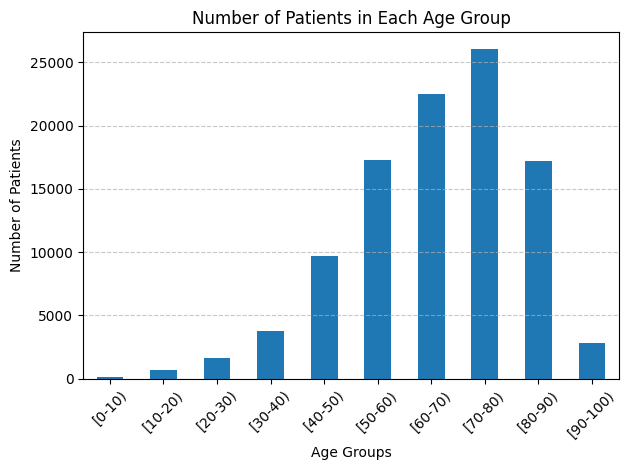

In [40]:
#Number of patients in each group
import pandas as pd
import matplotlib.pyplot as plt 

age_group_counts = df['age'].value_counts().sort_index()

age_group_counts.plot(kind='bar',title='Number of Patients in Each Age Group')

# Add labels and improve layout
plt.xlabel('Age Groups')
plt.ylabel('Number of Patients')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

gender
Female             54708
Male               47055
Unknown/Invalid        3
Name: count, dtype: int64


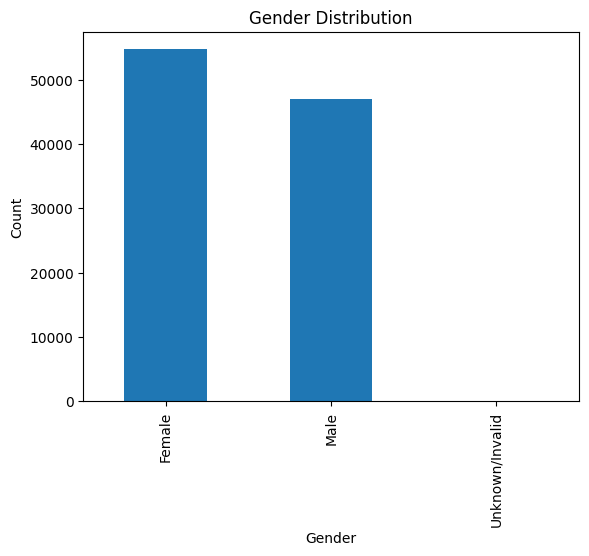

In [49]:
gender_counts = pd.read_csv(r"C:\Users\Asus\Desktop\diabetic_data.csv")['gender'].value_counts()
print(df['gender'].value_counts())

gender_counts.plot(kind='bar', title='Gender Distribution')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.show()


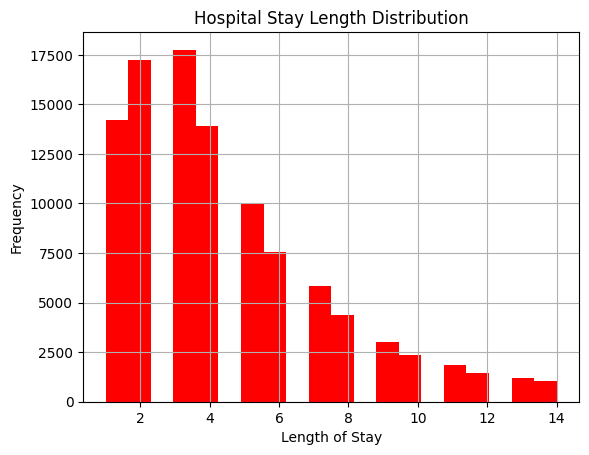

In [50]:
#Create a histogram to show the frequency of different lengths of stay in the hospital
pd.read_csv(r"C:\Users\Asus\Desktop\diabetic_data.csv")['time_in_hospital'].hist(bins=20, color='red')
plt.title('Hospital Stay Length Distribution')
plt.xlabel('Length of Stay')
plt.ylabel('Frequency')
plt.show()



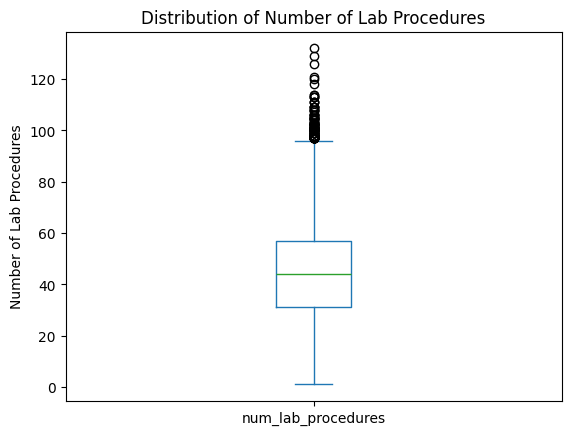

In [51]:
#Use a box plot to show the distribution of num_lab_procedures
pd.read_csv(r"C:\Users\Asus\Desktop\diabetic_data.csv")['num_lab_procedures'].plot(kind='box')
plt.title('Distribution of Number of Lab Procedures')
plt.ylabel('Number of Lab Procedures')
plt.show()


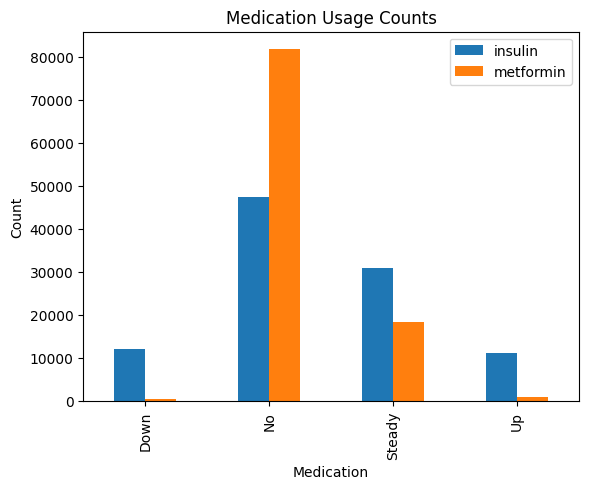

In [52]:
#Create a bar chart showing the counts of "Yes", "No", or "Steady" values for key medications like insulin, metformin, etc
df[['insulin', 'metformin']].apply(pd.Series.value_counts).plot(kind='bar')

# Add labels and title
plt.title('Medication Usage Counts')
plt.xlabel('Medication')
plt.ylabel('Count')
plt.show()

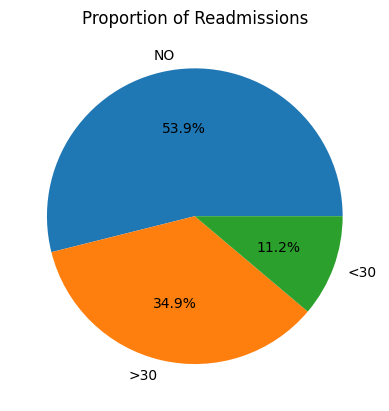

In [53]:
#Create a pie chart showing the proportions of patients readmitted within 30 days (<30), after 30 days (>30), or not at all (NO)
# Load dataset
df = pd.read_csv(r"C:\Users\Asus\Desktop\diabetic_data.csv")

# Count occurrences of readmission categories
readmission_counts = df['readmitted'].value_counts()

# Plot pie chart
readmission_counts.plot(kind='pie', autopct='%1.1f%%', title='Proportion of Readmissions')
plt.ylabel('')  # Hide the default ylabel
plt.show()

race
Caucasian          76099
AfricanAmerican    19210
?                   2273
Hispanic            2037
Other               1506
Asian                641
Name: count, dtype: int64


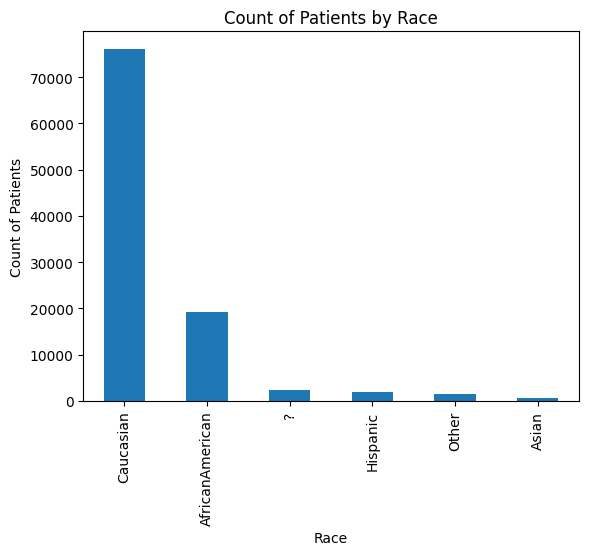

In [54]:
#Create a bar chart showing the count of patients by race
# Count occurrences of each race
race_counts = df['race'].value_counts()
print(race_counts)

# Plot bar chart
race_counts.plot(kind='bar',  title='Count of Patients by Race')
plt.xlabel('Race')
plt.ylabel('Count of Patients')
plt.show()

                    A1Cresult                                                \
admission_source_id      1.0  2.0  3.0  4.0  5.0  6.0   7.0  8.0  9.0  10.0   
race                                                                          
?                         140    0    0   32    0   67   166    0   12    1   
AfricanAmerican           601   30    6   57   18  163  2548    1    4    0   
Asian                      33    0    0    0    1    0    99    0    0    0   
Caucasian                3042   35   27  339   47  295  7957    2    7    6   
Hispanic                   89    3    0    6    1    0   365    1    0    0   
Other                      67    3    0    4    0    0   223    0    0    0   

                     ... weight                                                
admission_source_id  ...   8.0  9.0  10.0 11.0 13.0 14.0  17.0 20.0 22.0 25.0  
race                 ...                                                       
?                    ...      0   71    1    0  

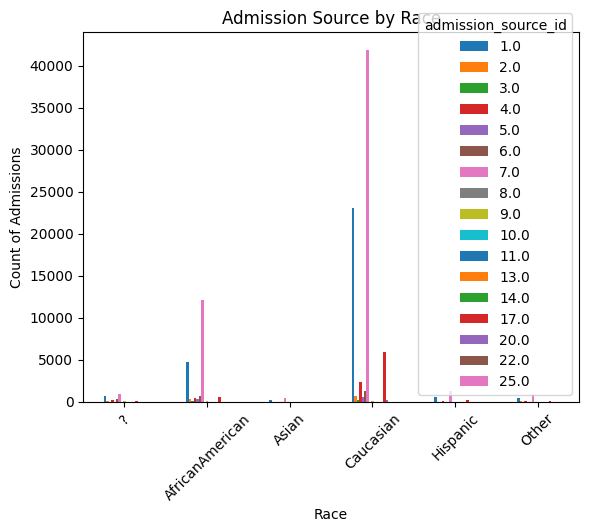

In [56]:
#Create a bar chart showing the count of patients by race
# Load dataset
df = pd.read_csv(r"C:\Users\Asus\Desktop\diabetic_data.csv")

# Create a pivot table to count admission sources by race

print(pd.pivot_table(df, index='race', columns='admission_source_id', aggfunc='count', fill_value=0))


# Plot stacked bar chart
race_admission_counts = pd.crosstab(df['race'], df['admission_source_id'])
race_admission_counts.plot(kind='bar', title='Admission Source by Race')
plt.xlabel('Race')
plt.ylabel('Count of Admissions')
plt.xticks(rotation=45)
plt.show()

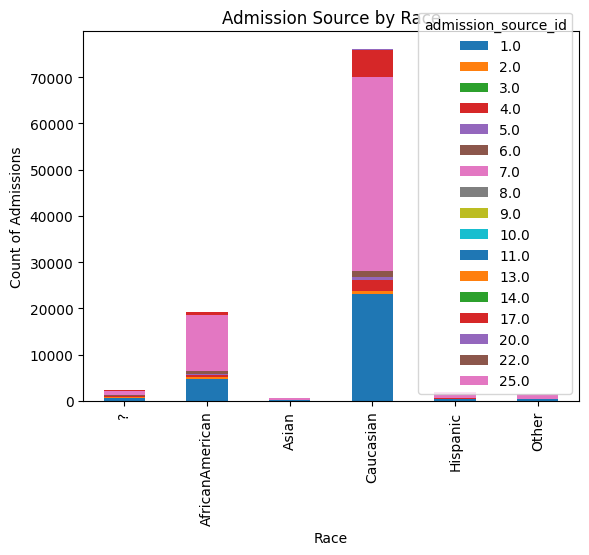

In [57]:
#Use a stacked bar chart to see which admission_source_id is common for each race


# Create a pivot table to count admission sources by race
race_admission_counts = pd.crosstab(df['race'], df['admission_source_id'])

# Plot stacked bar chart
race_admission_counts.plot(kind='bar', stacked=True, title='Admission Source by Race')
plt.xlabel('Race')
plt.ylabel('Count of Admissions')
plt.show()


medical_specialty
?                         49949
InternalMedicine          14635
Emergency/Trauma           7565
Family/GeneralPractice     7440
Cardiology                 5352
                          ...  
Proctology                    1
Speech                        1
SportsMedicine                1
Perinatology                  1
Neurophysiology               1
Name: count, Length: 73, dtype: int64


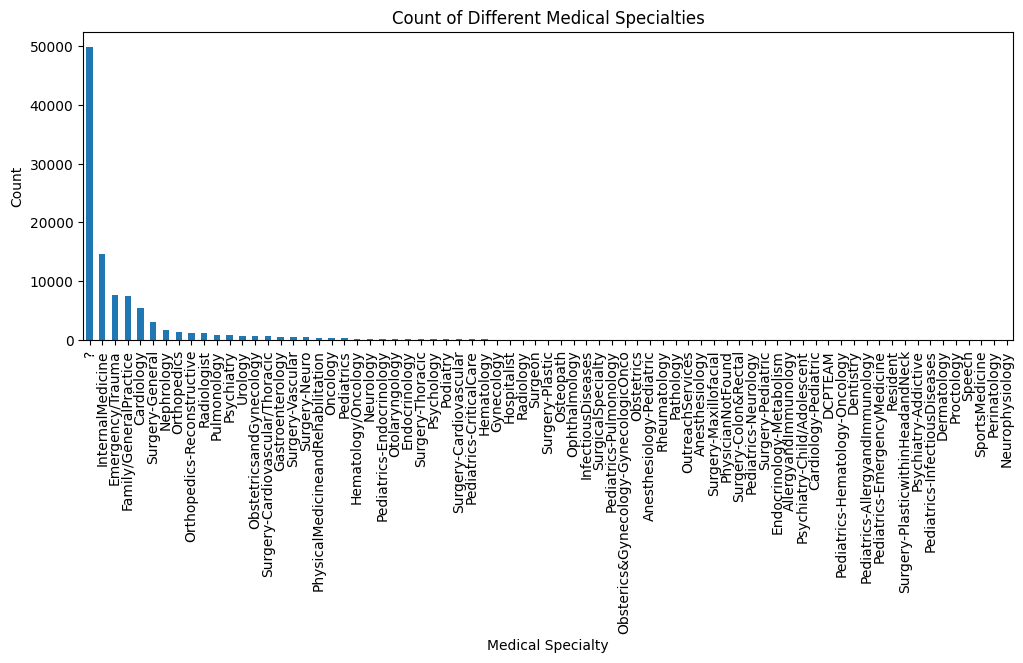

In [63]:
#Use a bar chart to show the counts of different medical_specialty values
# Count occurrences of each medical_specialty
specialty_counts = df['medical_specialty'].value_counts()
print(specialty_counts)

# Plot bar chart
specialty_counts.plot(figsize=(12,4) ,kind='bar', title='Count of Different Medical Specialties')
plt.xlabel('Medical Specialty')
plt.ylabel('Count')
plt.show()

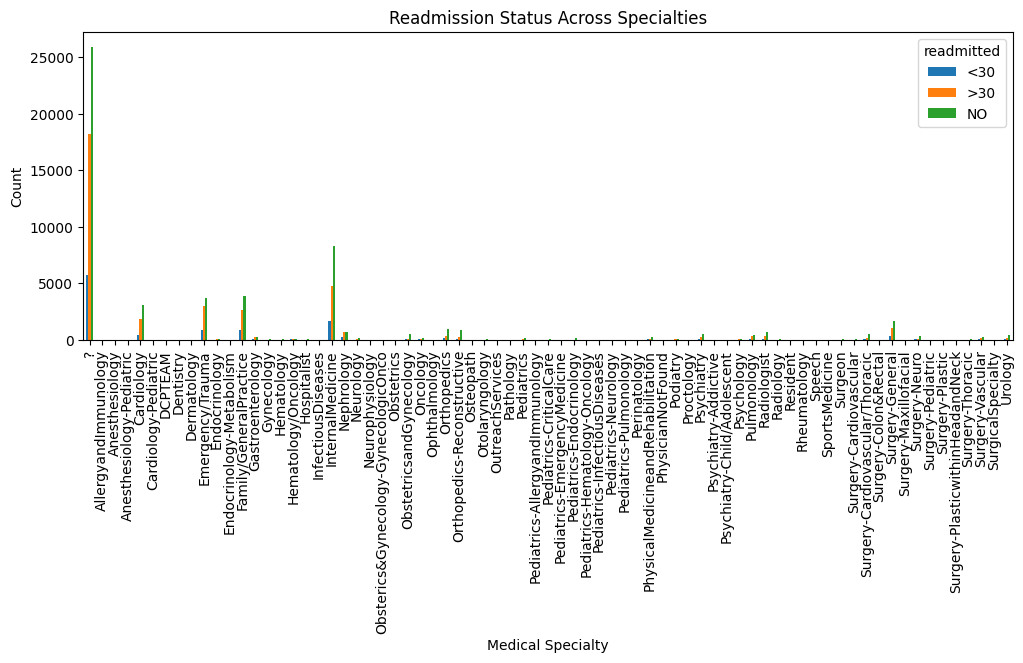

In [65]:
#Use a grouped bar chart to show readmitted status across specialties
# Group by medical_specialty and readmitted, then count occurrences
readmission_counts = df.groupby(['medical_specialty', 'readmitted']).size().unstack()

# Plot grouped bar chart
readmission_counts.plot(kind='bar', stacked=False, figsize=(12, 4))

# Add labels and title
plt.title('Readmission Status Across Specialties')
plt.xlabel('Medical Specialty')
plt.ylabel('Count')
plt.show()

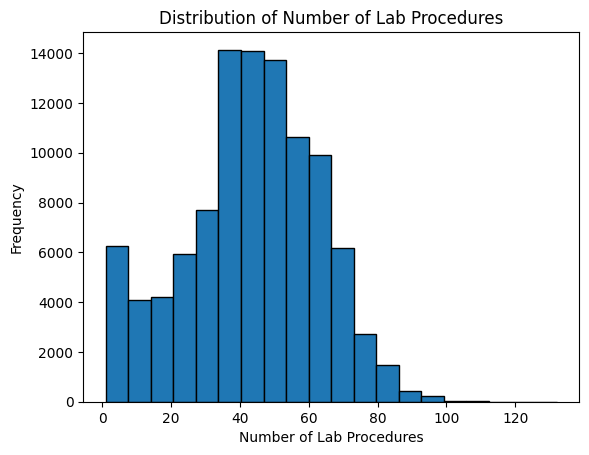

In [66]:
#visualise distribution of a numeric column

# Plot histogram to visualize the distribution of 'num_lab_procedures'
df['num_lab_procedures'].plot(kind='hist', bins=20,edgecolor='black')

# Add title and labels
plt.title('Distribution of Number of Lab Procedures')
plt.xlabel('Number of Lab Procedures')
plt.ylabel('Frequency')
plt.show()

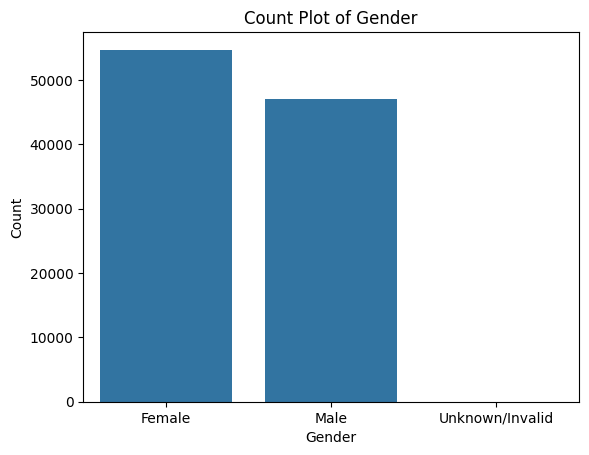

In [67]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
#Perform count plot of a categorical variable

#Plot count plot for a categorical variable (e.g., 'gender')
sns.countplot(x='gender', data=df)

# Add title and labels
plt.title('Count Plot of Gender')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.show()

### 1B.5: Exploratory Data Analysis (EDA) with Visualisations

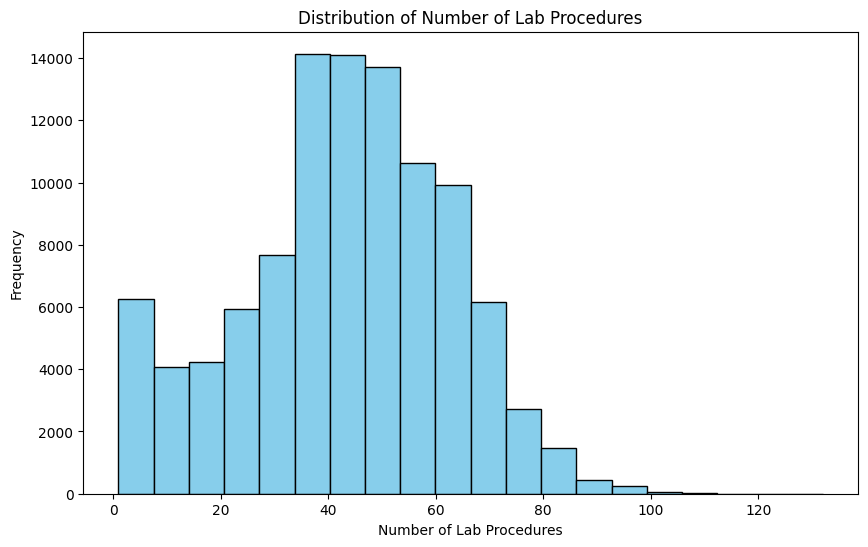

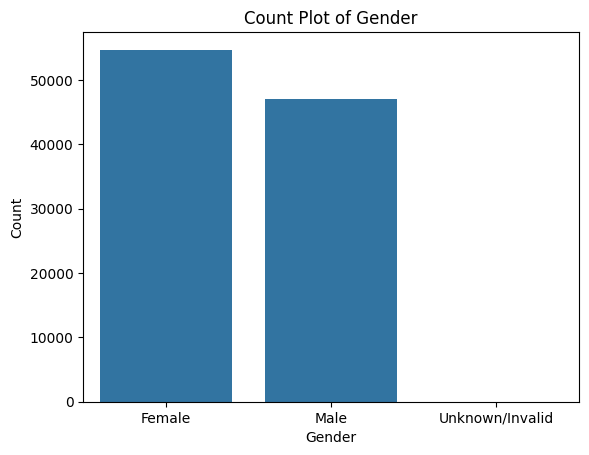

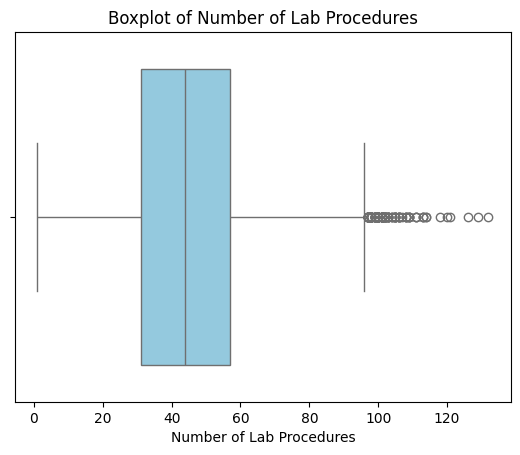

In [69]:
import matplotlib
import seaborn 

# Distribution of a numeric column
# Plot histogram to visualize the distribution of 'num_lab_procedures'
df['num_lab_procedures'].plot(kind='hist', bins=20, color='skyblue', edgecolor='black', figsize=(10, 6))

# Add title and labels
plt.title('Distribution of Number of Lab Procedures')
plt.xlabel('Number of Lab Procedures')
plt.ylabel('Frequency')
plt.show()

# Count plot of a categorical variable

# Plot count plot for a categorical variable (e.g., 'gender')
sns.countplot(x='gender', data=df)

# Add title and labels
plt.title('Count Plot of Gender')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.show()

# Boxplot to detect outliers

# Create boxplot to detect outliers in 'num_lab_procedures'
sns.boxplot(x=df['num_lab_procedures'], color='skyblue')

# Add title and labels
plt.title('Boxplot of Number of Lab Procedures')
plt.xlabel('Number of Lab Procedures')
plt.show()

_________
## *Task 2: Data Processing
### Task Description
Create a robust data preprocessing pipeline to handle missing values, encode categorical variables, and scale numerical features.

### **Task 2.1: Initial Cleaning and Pre-processing**

#### 2.1.1: Load and Visualise the Data
- Use pandas to load the dataset.
- Visualise the first few rows to understand the structure of the data.

   encounter_id  patient_nbr             race  gender      age weight  \
0     2278392.0      8222157        Caucasian  Female   [0-10)    NaN   
1      149190.0     55629189        Caucasian  Female  [10-20)      ?   
2       64410.0     86047875  AfricanAmerican  Female  [20-30)      ?   
3      500364.0     82442376        Caucasian    Male  [30-40)      ?   
4       16680.0     42519267        Caucasian    Male  [40-50)      ?   

   admission_type_id  discharge_disposition_id  admission_source_id  \
0                6.0                      25.0                  1.0   
1                1.0                       1.0                  7.0   
2                1.0                       1.0                  7.0   
3                1.0                       1.0                  7.0   
4                1.0                       1.0                  7.0   

   time_in_hospital  ... citoglipton insulin  glyburide-metformin  \
0               1.0  ...          No      No                   No

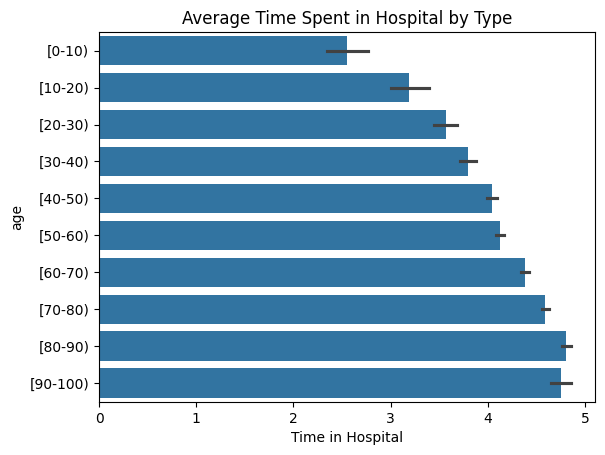

In [70]:
# Importing required Python libraries
import pandas as pd
import numpy as ns
import seaborn as sns
import matplotlib.pyplot as plt

# Loading the data
path=r"C:\Users\Asus\Desktop\diabetic_data.csv"

file=pd.read_csv(path)

# visualise the first few rows of the data
print(file.head())
  #<add your code here>
sns.barplot(data= file , x = 'time_in_hospital',y='age')
plt.xlabel("Time in Hospital")
plt.ylabel("age")
plt.title("Average Time Spent in Hospital by Type")
plt.show()

#### 2.1.2: Display Data Types and Check for Incorrect Types

- Use the .dtypes attribute to display each column's data type.
- Identify columns that have unexpected data types (e.g., numeric data stored as strings).

In [71]:
# Display data types of each column
print(file.dtypes)

for column in file.select_dtypes(include=['object']).columns:
    print(column)



encounter_id                float64
patient_nbr                   int64
race                         object
gender                       object
age                          object
weight                       object
admission_type_id           float64
discharge_disposition_id    float64
admission_source_id         float64
time_in_hospital            float64
payer_code                   object
medical_specialty            object
num_lab_procedures          float64
num_procedures              float64
num_medications             float64
number_outpatient           float64
number_emergency            float64
number_inpatient            float64
diag_1                       object
diag_2                       object
diag_3                       object
number_diagnoses            float64
max_glu_serum                object
A1Cresult                    object
metformin                    object
repaglinide                  object
nateglinide                  object
chlorpropamide              

#### 2.1.3: Identify and Remove Duplicate Rows

- Check for duplicate rows.
- If duplicates exist, remove them 

In [72]:
for i in file.duplicated():
    count=0
    if i==True:
        count+=1




print(f"Number of duplicate rows: {count}")

# Drop duplicates if any
x=file.drop_duplicates()
print(x)


Number of duplicate rows: 0
        encounter_id  patient_nbr             race  gender      age weight  \
0          2278392.0      8222157        Caucasian  Female   [0-10)    NaN   
1           149190.0     55629189        Caucasian  Female  [10-20)      ?   
2            64410.0     86047875  AfricanAmerican  Female  [20-30)      ?   
3           500364.0     82442376        Caucasian    Male  [30-40)      ?   
4            16680.0     42519267        Caucasian    Male  [40-50)      ?   
...              ...          ...              ...     ...      ...    ...   
101762   443847548.0    100162476  AfricanAmerican    Male  [70-80)      ?   
101763   443847782.0     74694222  AfricanAmerican  Female  [80-90)      ?   
101764   443854148.0     41088789        Caucasian    Male  [70-80)      ?   
101765   443857166.0     31693671        Caucasian  Female  [80-90)      ?   
101766   443867222.0    175429310        Caucasian    Male  [70-80)      ?   

        admission_type_id  discharg

### Task 2.2: Handling Metadata and Missing Values
#### 2.2.1: Identify Metadata from the Dataset
Metadata includes information like column names, data types, and any additional descriptive information.

In [73]:
# Display metadata including column names and data types
print(file.info())
print(file.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101767 entries, 0 to 101766
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   encounter_id              101765 non-null  float64
 1   patient_nbr               101767 non-null  int64  
 2   race                      101766 non-null  object 
 3   gender                    101766 non-null  object 
 4   age                       101766 non-null  object 
 5   weight                    101765 non-null  object 
 6   admission_type_id         101766 non-null  float64
 7   discharge_disposition_id  101766 non-null  float64
 8   admission_source_id       101766 non-null  float64
 9   time_in_hospital          101766 non-null  float64
 10  payer_code                101766 non-null  object 
 11  medical_specialty         101766 non-null  object 
 12  num_lab_procedures        101766 non-null  float64
 13  num_procedures            101766 non-null  f


#### 2.2.2: Analyse Different Types of Data
- Categorize columns based on their data types (e.g., numerical, categorical).
- Describe the significance of each data type and how it might impact data processing.

In [74]:
# Describe data to understand different types
numerical_columns=file.select_dtypes(include=['int64','float64']).columns.tolist
categorial_columns=file.select_dtypes(include=['object']).columns.tolist
print(numerical_columns)
print(categorial_columns)


<bound method IndexOpsMixin.tolist of Index(['encounter_id', 'patient_nbr', 'admission_type_id',
       'discharge_disposition_id', 'admission_source_id', 'time_in_hospital',
       'num_lab_procedures', 'num_procedures', 'num_medications',
       'number_outpatient', 'number_emergency', 'number_inpatient',
       'number_diagnoses'],
      dtype='object')>
<bound method IndexOpsMixin.tolist of Index(['race', 'gender', 'age', 'weight', 'payer_code', 'medical_specialty',
       'diag_1', 'diag_2', 'diag_3', 'max_glu_serum', 'A1Cresult', 'metformin',
       'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride',
       'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide',
       'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone',
       'tolazamide', 'examide', 'citoglipton', 'insulin',
       'glyburide-metformin', 'glipizide-metformin',
       'glimepiride-pioglitazone', 'metformin-rosiglitazone',
       'metformin-pioglitazone', 'change', 'diabetesMed',

#### 2.2.3: Identify Missing Values
- Missing values can significantly impact model performance and analysis.
- Count missing values in each column.
- Calculate the percentage of missing values.

In [75]:
# Identify and calculate the percentage of missing values
missing=file.isnull().sum()
print(missing)
rows=file.shape[0]
percentage=(missing/rows)*100
print(percentage)
print("Missing values (in percentage) for each column:\n",  )

encounter_id                    2
patient_nbr                     0
race                            1
gender                          1
age                             1
weight                          2
admission_type_id               1
discharge_disposition_id        1
admission_source_id             1
time_in_hospital                1
payer_code                      1
medical_specialty               1
num_lab_procedures              1
num_procedures                  1
num_medications                 1
number_outpatient               1
number_emergency                1
number_inpatient                1
diag_1                          1
diag_2                          1
diag_3                          1
number_diagnoses                1
max_glu_serum               96421
A1Cresult                   84749
metformin                       1
repaglinide                     1
nateglinide                     1
chlorpropamide                  1
glimepiride                     1
acetohexamide 

#### 2.2.4: Splitting Data for Analysis
Splitting data ensures that models are trained on one portion of the data and tested on another, unseen portion.

In [76]:
from sklearn.model_selection import train_test_split


# Features and target
X = file.drop(columns=['time_in_hospital'])
y = file['time_in_hospital']

# Split dataset
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.5,random_state=42)

___________
## *Task 3: Machine Learning
### Task Description
Implement various machine learning algorithms for regression, classification and clustering and evaluating them.

### **Task 3.1: Implementing Regression Baseline**
#### 3.1.1: Loading the data
- Use pandas to load the dataset.

In [72]:
import pandas as pd
from pandas.plotting import scatter_matrix
# Reload the dataset as a Pandas DataFrame
file_path = r"C:\Users\Asus\Desktop\diabetic_data.csv"
data = pd.read_csv(file_path)
data = data.drop(['max_glu_serum','weight', 'A1Cresult','payer_code','encounter_id','metformin-pioglitazone','metformin-rosiglitazone','glimepiride-pioglitazone'
                  ,'glipizide-metformin','glyburide-metformin','citoglipton','examide','tolazamide','troglitazone','miglitol','acarbose','rosiglitazone','pioglitazone','tolbutamide','glyburide','acetohexamide',
                  'glimepiride','chlorpropamide','nateglinide','repaglinide','diag_3','diag_2','diag_1','medical_specialty','number_emergency'],axis=1)
data = data.dropna()
# I deleted these columns from my data to prevent overfitting. Additionally, most of these columns had too many missing values, making them insufficient.

In [73]:
data['admission_type_id'].value_counts()

admission_type_id
1.0    53990
3.0    18869
2.0    18480
6.0     5291
5.0     4785
8.0      320
7.0       21
4.0       10
Name: count, dtype: int64

In [74]:
data['admission_type_id']=data['admission_type_id'].replace(5,8)
data['admission_type_id']=data['admission_type_id'].replace(6,8)
data['admission_type_id'].value_counts()
# 1- Emergency
# 2- Urgent
# 3- Elective
# 4- Newborn
# 5- Not Available
# 6- Null  
# 7- Trauma Center
# 8- Not Mapped 

# Because items 5, 6, and 8 have the same meaning and are known as a missing value count, consider these 3 items as 1 item.



admission_type_id
1.0    53990
3.0    18869
2.0    18480
8.0    10396
7.0       21
4.0       10
Name: count, dtype: int64

In [75]:

# Convert categorical data into numerical data without adding any extra columns.
data['diabetesMed']=data['diabetesMed'].map({'No':0,'Yes':1})
data['change']=data['change'].map({'No':0,'Ch':1})
data['insulin']=data['insulin'].map({'No':0,'Steady':1,'Down':2,'Up':3})
data['glipizide']=data['glipizide'].map({'No':0,'Steady':1,'Down':2,'Up':3})
data['metformin']=data['metformin'].map({'No':0,'Steady':1,'Down':2,'Up':3})
data['readmitted']=data['readmitted'].map({'NO':0,'>30':1,'<30':2})
for col in data.columns:
    print(f"Unique values in '{col}':")
    print(data[col].unique())
    print()




Unique values in 'patient_nbr':
[  8222157  55629189  86047875 ... 140199494 120975314 175429310]

Unique values in 'race':
['Caucasian' 'AfricanAmerican' '?' 'Other' 'Asian' 'Hispanic']

Unique values in 'gender':
['Female' 'Male' 'Unknown/Invalid']

Unique values in 'age':
['[0-10)' '[10-20)' '[20-30)' '[30-40)' '[40-50)' '[50-60)' '[60-70)'
 '[70-80)' '[80-90)' '[90-100)']

Unique values in 'admission_type_id':
[8. 1. 2. 3. 4. 7.]

Unique values in 'discharge_disposition_id':
[25.  1.  3.  6.  2.  5. 11.  7. 10.  4. 14. 18.  8. 13. 12. 16. 17. 22.
 23.  9. 20. 15. 24. 28. 19. 27.]

Unique values in 'admission_source_id':
[ 1.  7.  2.  4.  5.  6. 20.  3. 17.  8.  9. 14. 10. 22. 11. 25. 13.]

Unique values in 'time_in_hospital':
[ 1.  3.  2.  4.  5. 13. 12.  9.  7. 10.  6. 11.  8. 14.]

Unique values in 'num_lab_procedures':
[ 41.  59.  11.  44.  51.  31.  70.  73.  68.  33.  47.  62.  60.  55.
  49.  75.  45.  29.  35.  42.  66.  36.  19.  64.  25.  53.  52.  87.
  27.  37.  46.  28.

In [76]:
# Try to make these columns clearer and more concise.
discharge_mapping = {
    1: 1,  # Home
    2: 2, 3: 2, 4: 2, 5: 2,  # Transfer
    6: 1, 8: 1,  # Home
    7: 5, 9: 5, 10: 5, 12: 5, 18: 5, 25: 5, 26: 5, 28: 5, 29: 5,  # Other
    11: 4, 19: 4, 20: 4, 21: 4,  # Expired
    13: 3, 14: 3,  # Hospice
    15: 2, 16: 2, 17: 2, 22: 2, 23: 2, 24: 2, 27: 2, 30: 2  # Transfer
}


data['discharge_disposition_id'] = data['discharge_disposition_id'].map(discharge_mapping)


data['discharge_disposition_id'].value_counts()

discharge_disposition_id
1    73244
2    20627
5     5472
4     1652
3      771
Name: count, dtype: int64

******************************This part corresponds to section (Feature Engineering and Feature Selection)  3.4.2: Generate Statistical Features, which I have completed in this cell*************

count    101766.000000
mean          2.259026
std           2.442109
min           1.000000
25%           1.000000
50%           1.000000
75%           3.000000
max          40.000000
Name: visit, dtype: float64

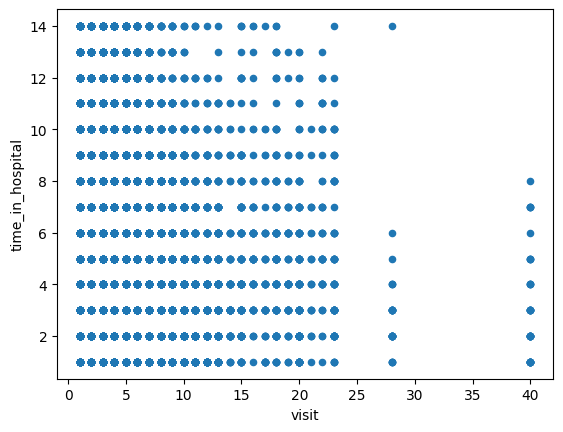

In [77]:
# Patient_num column
# data['patient_nbr'].value_counts()
data['visit']=data.groupby('patient_nbr')['patient_nbr'].transform('count')
data['visit'].describe()
data.plot.scatter(x='visit',y='time_in_hospital')

data['visit'].describe()


In [78]:
# As we can see, there is no difference between a person who comes for the first time and one who comes multiple times.
# A person visiting for the first time could stay between 1 and 14 days.
# Similarly, a patient who visits 20 times could stay between 1 and 13 days. Therefore, there is no significant correlation or coefficient associated with this column, so we can delete it.
data=data.drop(['visit','patient_nbr'],axis=1)
data.columns

Index(['race', 'gender', 'age', 'admission_type_id',
       'discharge_disposition_id', 'admission_source_id', 'time_in_hospital',
       'num_lab_procedures', 'num_procedures', 'num_medications',
       'number_outpatient', 'number_inpatient', 'number_diagnoses',
       'metformin', 'glipizide', 'insulin', 'change', 'diabetesMed',
       'readmitted'],
      dtype='object')

In [79]:
# Try to make these features clearer and simpler for the machine learning model.
data['admission_source_id'] = data['admission_source_id'].map({
    1: 1,
    2: 2,
    3: 3,
    4: 4,
    5: 4,
    6: 4,
    7: 7,
    8: 8,
    9: 13,
    10: 4,
    11: 11,
    12: 11,
    13: 11,
    14: 11,
    15: 9,
    17: 9,
    18: 4,
    19: 12,
    20: 9,
    21: 9,
    22: 4,
    23: 11,
    24: 14,
    25: 4,
    26: 4
})

data['admission_source_id'].value_counts()
# 1- Physician Referral
# 2- Clinic Referral
# 3- HMO Referral
# 4- Transfer from a hospital
# 7- Emergency Room
# 8- Court/Law Enforcement
# 9- Not Available
# 11-Normal Delivery
# 13-Sick Baby

admission_source_id
7     57494
1     29565
9      6942
4      6328
2      1104
3       187
13      125
8        16
11        5
Name: count, dtype: int64

In [80]:
# race column
data['race'].unique()

array(['Caucasian', 'AfricanAmerican', '?', 'Other', 'Asian', 'Hispanic'],
      dtype=object)

In [81]:
# converting race column to numerical
data['race'] = data['race'].fillna('Other')
data['race']=data['race'].replace('?','Other')
data['race']=data['race'].map({'AfricanAmerican':1, 'Asian':4, 'Caucasian':2, 'Hispanic':3, 'Other':0})

In [82]:
data['age']

0          [0-10)
1         [10-20)
2         [20-30)
3         [30-40)
4         [40-50)
           ...   
101762    [70-80)
101763    [80-90)
101764    [70-80)
101765    [80-90)
101766    [70-80)
Name: age, Length: 101766, dtype: object

******************************This part corresponds to section (Feature Engineering and Feature Selection)  3.4.1: Features Engineering, which I have completed in this cell*************

In [83]:
# convert age column to numeric 
def convert_age_to_numeric(age_range):
    if isinstance(age_range, str):  # Check if the value is a string
        start, end = age_range.strip("[]()").split('-')
        start, end = int(start), int(end)
        return (start + end) / 2  # Calculate the average
    else:
        return None  # Handle non-string values (e.g., NaN)



data['age'] = data['age'].apply(convert_age_to_numeric)

In [84]:
data.shape

(101766, 19)

In [85]:
# gender
data['gender']=data['gender'].map({'Male':1, 'Female':0,'Unknown/Invalid':0})

In [86]:
# Delete any missing value
data=data.dropna()
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 101766 entries, 0 to 101766
Data columns (total 19 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   race                      101766 non-null  int64  
 1   gender                    101766 non-null  int64  
 2   age                       101766 non-null  float64
 3   admission_type_id         101766 non-null  float64
 4   discharge_disposition_id  101766 non-null  int64  
 5   admission_source_id       101766 non-null  int64  
 6   time_in_hospital          101766 non-null  float64
 7   num_lab_procedures        101766 non-null  float64
 8   num_procedures            101766 non-null  float64
 9   num_medications           101766 non-null  float64
 10  number_outpatient         101766 non-null  float64
 11  number_inpatient          101766 non-null  float64
 12  number_diagnoses          101766 non-null  float64
 13  metformin                 101766 non-null  int64 

In [87]:
# As we can see there are all numerical data
data

,race,gender,age,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_inpatient,number_diagnoses,metformin,glipizide,insulin,change,diabetesMed,readmitted
0,2,0,5.0,8.0,5,1,1.0,41.0,0.0,1.0,0.0,0.0,1.0,0,0,0,0,0,0
1,2,0,15.0,1.0,1,7,3.0,59.0,0.0,18.0,0.0,0.0,9.0,0,0,3,1,1,1
2,1,0,25.0,1.0,1,7,2.0,11.0,5.0,13.0,2.0,1.0,6.0,0,1,0,0,1,0
3,2,1,35.0,1.0,1,7,2.0,44.0,1.0,16.0,0.0,0.0,7.0,0,0,3,1,1,0
4,2,1,45.0,1.0,1,7,1.0,51.0,0.0,8.0,0.0,0.0,5.0,0,1,1,1,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
101762,1,1,75.0,1.0,2,7,3.0,51.0,0.0,16.0,0.0,0.0,9.0,1,0,2,1,1,1
101763,1,0,85.0,1.0,2,4,5.0,33.0,3.0,18.0,0.0,1.0,9.0,0,0,1,0,1,0
101764,2,1,75.0,1.0,1,7,1.0,53.0,0.0,9.0,1.0,0.0,13.0,1,0,2,1,1,0
101765,2,0,85.0,2.0,2,7,10.0,45.0,2.0,21.0,0.0,1.0,9.0,0,1,3,1,1,0


******************************This part corresponds to section (Feature Engineering and Feature Selection)  3.4.3: Feature Transformation, which I have completed in this cell*************

In [88]:
# scaling my data 
# from sklearn.preprocessing import StandardScaler

# df=pd.DataFrame(data)
# numerical_data = df.select_dtypes(include=['int64','float64'])
# scaler=StandardScaler()
# scaled_data=scaler.fit_transform(numerical_data)
# scaled_df=pd.DataFrame(scaled_data,columns=numerical_data.columns)


from sklearn.preprocessing import MinMaxScaler

df=pd.DataFrame(data)
numerical_data = df.select_dtypes(include=['int64','float64'])
scaler = MinMaxScaler()
scaled_data = scaler.fit_transform(data)
scaled_df=pd.DataFrame(scaled_data,columns=numerical_data.columns)



In [89]:
scaled_df

,race,gender,age,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_inpatient,number_diagnoses,metformin,glipizide,insulin,change,diabetesMed,readmitted
0,0.50,0.0,0.000000,1.000000,1.00,0.00,0.000000,0.305344,0.000000,0.0000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0
1,0.50,0.0,0.111111,0.000000,0.00,0.50,0.153846,0.442748,0.000000,0.2125,0.000000,0.000000,0.533333,0.000000,0.000000,1.000000,1.0,1.0,0.5
2,0.25,0.0,0.222222,0.000000,0.00,0.50,0.076923,0.076336,0.833333,0.1500,0.047619,0.047619,0.333333,0.000000,0.333333,0.000000,0.0,1.0,0.0
3,0.50,1.0,0.333333,0.000000,0.00,0.50,0.076923,0.328244,0.166667,0.1875,0.000000,0.000000,0.400000,0.000000,0.000000,1.000000,1.0,1.0,0.0
4,0.50,1.0,0.444444,0.000000,0.00,0.50,0.000000,0.381679,0.000000,0.0875,0.000000,0.000000,0.266667,0.000000,0.333333,0.333333,1.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
101761,0.25,1.0,0.777778,0.000000,0.25,0.50,0.153846,0.381679,0.000000,0.1875,0.000000,0.000000,0.533333,0.333333,0.000000,0.666667,1.0,1.0,0.5
101762,0.25,0.0,0.888889,0.000000,0.25,0.25,0.307692,0.244275,0.500000,0.2125,0.000000,0.047619,0.533333,0.000000,0.000000,0.333333,0.0,1.0,0.0
101763,0.50,1.0,0.777778,0.000000,0.00,0.50,0.000000,0.396947,0.000000,0.1000,0.023810,0.000000,0.800000,0.333333,0.000000,0.666667,1.0,1.0,0.0
101764,0.50,0.0,0.888889,0.142857,0.25,0.50,0.692308,0.335878,0.333333,0.2500,0.000000,0.047619,0.533333,0.000000,0.333333,1.000000,1.0,1.0,0.0


array([[<Axes: xlabel='num_medications', ylabel='num_medications'>,
        <Axes: xlabel='num_lab_procedures', ylabel='num_medications'>,
        <Axes: xlabel='discharge_disposition_id', ylabel='num_medications'>],
       [<Axes: xlabel='num_medications', ylabel='num_lab_procedures'>,
        <Axes: xlabel='num_lab_procedures', ylabel='num_lab_procedures'>,
        <Axes: xlabel='discharge_disposition_id', ylabel='num_lab_procedures'>],
       [<Axes: xlabel='num_medications', ylabel='discharge_disposition_id'>,
        <Axes: xlabel='num_lab_procedures', ylabel='discharge_disposition_id'>,
        <Axes: xlabel='discharge_disposition_id', ylabel='discharge_disposition_id'>]],
      dtype=object)

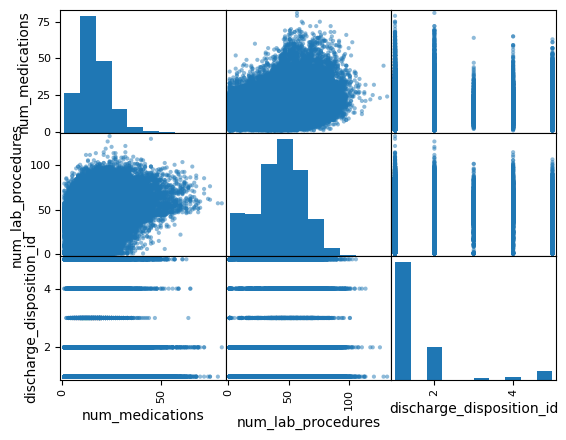

In [90]:
s=['num_medications','num_lab_procedures','discharge_disposition_id']
scatter_matrix(data[s])

3.4.4: Feature Selection

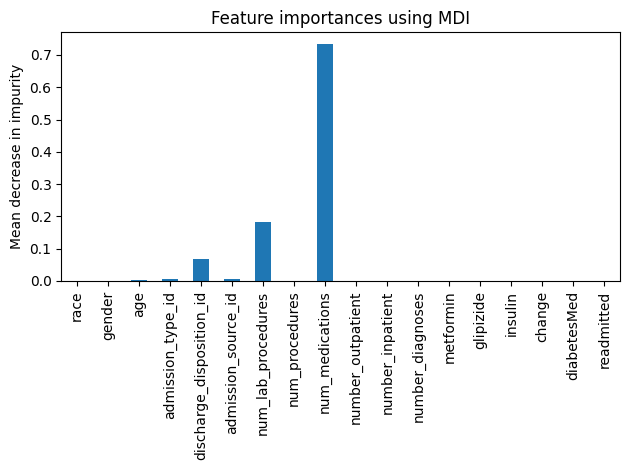

In [91]:
from sklearn.ensemble import RandomForestRegressor
import matplotlib.pyplot as plt
import pandas as pd

# Fit Random Forest model
rfs=RandomForestRegressor(n_estimators=100,max_depth=4)
rfs.fit(scaled_df.drop('time_in_hospital',axis=1),scaled_df['time_in_hospital'])
# Get feature importance
# print(scaled_df.drop('time_in_hospital',axis=1).columns)
importances = rfs.feature_importances_

# Plot feature importance


forest_importances = pd.Series(importances, index=scaled_df.drop('time_in_hospital',axis=1).columns)

fig, ax = plt.subplots()
forest_importances.plot.bar( ax=ax)
ax.set_title("Feature importances using MDI")
ax.set_ylabel("Mean decrease in impurity")
fig.tight_layout()

In [92]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import train_test_split
import numpy as np

# Defining features (X) and target (y)
x = data[['num_medications','num_lab_procedures','discharge_disposition_id']]
y = data['time_in_hospital'] #it should be numerical

# Split the data into train and test sets
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

# Train the Random Forest Regressor
model = RandomForestRegressor(random_state=42)
model.fit(x_train, y_train)

# Make predictions
y_pred = model.predict(x_test)

# Calculate MAE
mae_r = mean_absolute_error(y_test, y_pred)

# Calculate MSE
mse_r = mean_squared_error(y_test, y_pred)

print(f"Mean Absolute Error random forest (MAE): {mae_r}")
print(f"Mean Squared Error random forest (MSE): {mse_r}")


Mean Absolute Error random forest (MAE): 1.9542598175162278
Mean Squared Error random forest (MSE): 6.6968632369710495


#### 3.1.2: Start to implement Linear Regression as a baseline model

In [93]:
# importing requires sklearn packages for implementing linear regression
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import OneHotEncoder,OrdinalEncoder
import pandas as pd

# Defining features (X) and target (y)
x = data[['num_medications','num_lab_procedures','discharge_disposition_id']]
y = data['time_in_hospital'] #it should be numerical

#handling missing value
x = x.fillna(0)
y = y.fillna(y.mean()) #replacing missing value with mean


# Spliting data into training and testing sets
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2,random_state=42)

# Initialising and training Linear Regression model
linear_model = LinearRegression()
linear_model.fit(x_train,y_train)


# Predictions
y_pred = linear_model.predict(x_test)

# Evaluation
mae =mean_absolute_error(y_test ,y_pred)

mse = mean_squared_error(y_pred, y_test) 

print(f'Linear Regression MAE: {mae}')
print(f'Linear Regression MSE: {mse}')


Linear Regression MAE: 1.9283576643073645
Linear Regression MSE: 6.393851685399885


##### You could try other linear models as well, such as Ridge, Lasso, useful information can be found [here](https://scikit-learn.org/stable/modules/linear_model.html#linear-model).

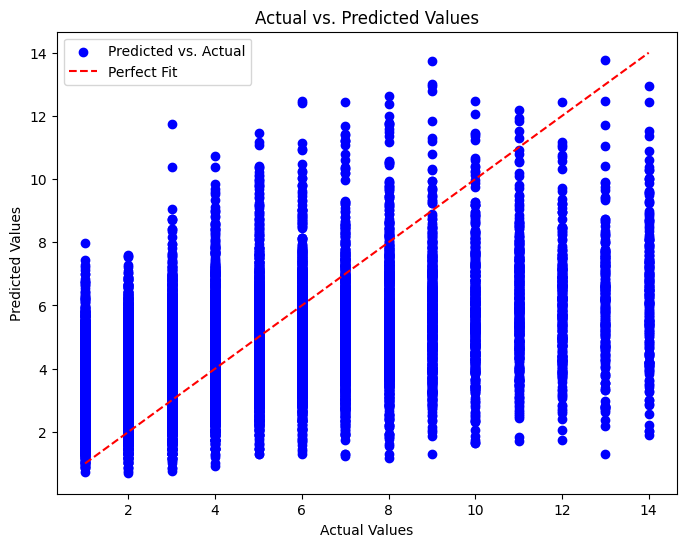

In [94]:
plt.figure(figsize=(8, 6))

# Scatter plot of actual vs. predicted
plt.scatter(y_test, y_pred, color='blue', label='Predicted vs. Actual')

# Add a diagonal line (perfect predictions)
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color='red', linestyle='--', label='Perfect Fit')

# Add labels and title
plt.title('Actual vs. Predicted Values')
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.legend()

plt.show()


#### 3.1.3: Visualise the output for linear regression

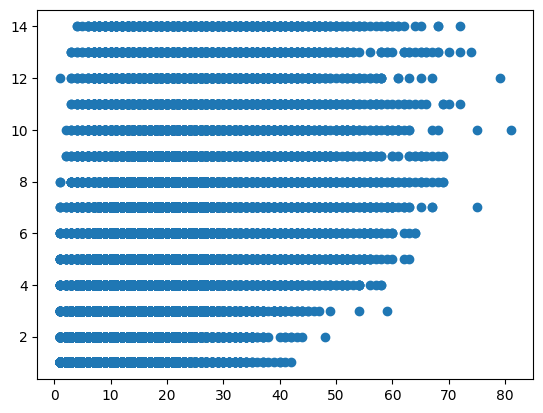

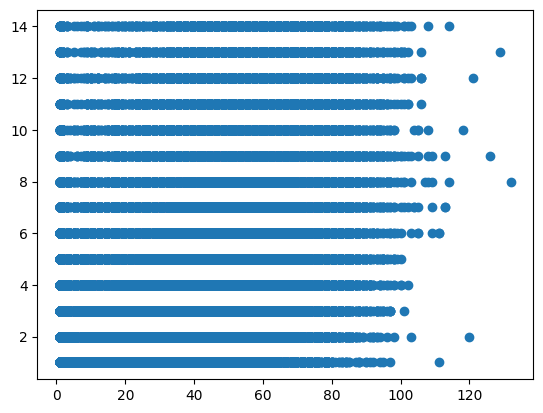

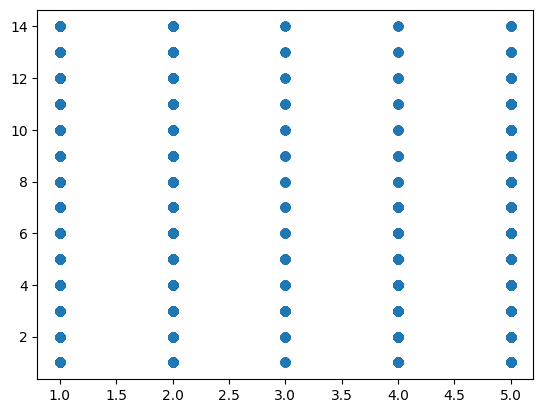

In [95]:
import matplotlib.pyplot as plt
x.shape[1]
s=['num_medications','num_lab_procedures','discharge_disposition_id']
for i in range(x.shape[1]):
    plt.scatter(x[s[i]],y)
    plt.show()
    plt.close()

#### 3.1.4: Implement Decision Tree Regression for Non-linear Relationships

In [96]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.model_selection import train_test_split


x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

# Create a DecisionTreeRegressor
dt = DecisionTreeRegressor(random_state=42)

# Define the parameter grid
param_grid = {
    'criterion': ['absolute_error', 'squared_error'],  # Splitting criteria
    'max_depth': [None,5,10,11,12,13,14],  # Maximum depth of the tree
    'min_samples_split': [10,11,12,13,14],  # Minimum samples to split a node
    'min_samples_leaf': [1, 2] # Minimum samples in a leaf
    # 'max_features': [None, 'sqrt', 'log2'] # Number of features to consider

}

# Use GridSearchCV to find the best parameters
grid_search = GridSearchCV(estimator=dt, param_grid=param_grid, scoring='neg_mean_squared_error', cv=3, verbose=1, n_jobs=-1)
grid_search.fit(x_train, y_train)

# Print the best parameters and the best score
print("Best Parameters:", grid_search.best_params_)
print("Best Score:", grid_search.best_score_)

# Evaluate the best model on the test set
best_model = grid_search.best_estimator_
y_pred = best_model.predict(x_test)
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
print("Test Set MSE:", mse)
print("Test Set MAE:", mae)

Fitting 3 folds for each of 140 candidates, totalling 420 fits
Best Parameters: {'criterion': 'squared_error', 'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 10}
Best Score: -6.442244237735186
Test Set MSE: 6.261203221903887
Test Set MAE: 1.90633603783896


c:\Users\Asus\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\ma\core.py:2881: RuntimeWarning: invalid value encountered in cast
  _data = np.array(data, dtype=dtype, copy=copy,


In [97]:
# importing requires sklearn packages for implementing regression
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=42)


# Initialising and training Decision Tree Regressor
tree_model = DecisionTreeRegressor(random_state=42,max_depth=5,min_samples_leaf=1,min_samples_split=10,criterion='squared_error',)
tree_model.fit(x_train, y_train)


# Predictions
y_pred_tree = tree_model.predict(x_test)

# Evaluation

mae_tree = mean_absolute_error(y_test, y_pred_tree)
mse_tree = mean_squared_error(y_test, y_pred_tree)

print(f"Decision Tree Regression MAE: {mae_tree}")
print(f"Decision Tree Regression MSE: {mse_tree}")

Decision Tree Regression MAE: 1.9144411227396965
Decision Tree Regression MSE: 6.350824362109451


#### 3.1.5: Implement Gradient Boosting Regression

In [98]:
# importing requires sklearn packages for implementing Gradient Boosting Regressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error


# Initialising and training Gradient Boosting Regressor
gboost_model = GradientBoostingRegressor(n_estimators=1000,random_state=42,learning_rate=0.05)
gboost_model.fit(x_train, y_train)

# Predictions
y_pred_gboost = gboost_model.predict(x_test)

# Evaluation
mae_gboost = mean_absolute_error(y_test,y_pred_gboost)
mse_gboost = mean_squared_error(y_test,y_pred_gboost)

print(f"Gradient Boosting Regression MAE: {mae_gboost}")
print(f"Gradient Boosting Regression MSE: {mse_gboost}")

Gradient Boosting Regression MAE: 1.8746598207659466
Gradient Boosting Regression MSE: 6.137248986594442


#### 3.1.6: Implement XGBoost Regression

In [99]:
# importing requires packages
import xgboost as XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error


# Initialize and train XGBoost Regressor
xgboost_model = XGBRegressor.XGBRegressor(n_estimators=1000,max_depth=5,learning_rate=0.05,random_state=42)
xgboost_model.fit(x_train, y_train)

# Predictions
y_pred_xgboost = xgboost_model.predict(x_test)

# Evaluation
mae_xgboost = mean_absolute_error(y_test,y_pred_xgboost)
mse_xgboost = mean_squared_error(y_test,y_pred_xgboost)


print(f"XGBoost Regression - MAE: {mae_xgboost}, MSE: {mse_xgboost}")


XGBoost Regression - MAE: 1.8811291676289208, MSE: 6.184145045591111


#### 3.1.7: Visualise the output for non-linear regression
Try to plot histogram of features, useful information can be found [here](https://matplotlib.org/stable/gallery/statistics/hist.html)

#### 3.1.8: Evaluation and Model Comparison
compare the performance of all four models: Linear Regression, Decision Tree Regression, Gradient Boosting, and XGBoost. Summarise each model's performance using a comparison table.


In [100]:
# Sample comparison table
results = {
    "Model": ["Linear Regression", "Decision Tree", "Gradient Boosting", "XGBoost"],
    "MAE": [mae, mae_tree, mae_gboost, mae_xgboost],
    "MSE": [mse, mse_tree, mse_gboost, mse_xgboost]
}

results_df = pd.DataFrame(results)
print(results_df)

               Model       MAE       MSE
0  Linear Regression  1.906336  6.261203
1      Decision Tree  1.914441  6.350824
2  Gradient Boosting  1.874660  6.137249
3            XGBoost  1.881129  6.184145


#### Expected Output for model comparison in 3.1.8:

| Model | MAE | MSE |
|---|---|---|
| Linear Regression | 1.90 | 6.26 |
| Decision Tree     | 1.91 | 6.35 |
| Gradient Boosting | 1.87 | 6.13 |
| XGBoost           | 1.88 | 6.18 |

++++++++
### **3.2: Implementing Classification Baseline**


#### 3.2.1: Loading the data
- Use pandas to load the dataset.

In [101]:
## Loading the data

import pandas as pd
# Reload the dataset as a Pandas DataFrame
file_path = r"C:\Users\Asus\Desktop\diabetic_data.csv"
data = pd.read_csv(file_path)
categorial=data.select_dtypes(include=['object','category']).columns
data = data.drop(['max_glu_serum','weight', 'A1Cresult','payer_code','patient_nbr','encounter_id','metformin-pioglitazone','metformin-rosiglitazone','glimepiride-pioglitazone'
                  ,'glipizide-metformin','glyburide-metformin','citoglipton','examide','tolazamide','troglitazone','miglitol','acarbose','rosiglitazone','pioglitazone','tolbutamide','glyburide','acetohexamide',
                  'glimepiride','chlorpropamide','nateglinide','repaglinide','diag_3','diag_2','diag_1','metformin','glipizide','medical_specialty',],axis=1)
data = data.dropna()
data
    


,race,gender,age,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,insulin,change,diabetesMed,readmitted
0,Caucasian,Female,[0-10),6.0,25.0,1.0,1.0,41.0,0.0,1.0,0.0,0.0,0.0,1.0,No,No,No,NO
1,Caucasian,Female,[10-20),1.0,1.0,7.0,3.0,59.0,0.0,18.0,0.0,0.0,0.0,9.0,Up,Ch,Yes,>30
2,AfricanAmerican,Female,[20-30),1.0,1.0,7.0,2.0,11.0,5.0,13.0,2.0,0.0,1.0,6.0,No,No,Yes,NO
3,Caucasian,Male,[30-40),1.0,1.0,7.0,2.0,44.0,1.0,16.0,0.0,0.0,0.0,7.0,Up,Ch,Yes,NO
4,Caucasian,Male,[40-50),1.0,1.0,7.0,1.0,51.0,0.0,8.0,0.0,0.0,0.0,5.0,Steady,Ch,Yes,NO
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
101762,AfricanAmerican,Male,[70-80),1.0,3.0,7.0,3.0,51.0,0.0,16.0,0.0,0.0,0.0,9.0,Down,Ch,Yes,>30
101763,AfricanAmerican,Female,[80-90),1.0,4.0,5.0,5.0,33.0,3.0,18.0,0.0,0.0,1.0,9.0,Steady,No,Yes,NO
101764,Caucasian,Male,[70-80),1.0,1.0,7.0,1.0,53.0,0.0,9.0,1.0,0.0,0.0,13.0,Down,Ch,Yes,NO
101765,Caucasian,Female,[80-90),2.0,3.0,7.0,10.0,45.0,2.0,21.0,0.0,0.0,1.0,9.0,Up,Ch,Yes,NO


In [102]:
data['diabetesMed']=data['diabetesMed'].map({'No':0,'Yes':1})
data['change']=data['change'].map({'No':0,'Ch':1})
data['insulin']=data['insulin'].map({'No':0,'Steady':1,'Down':2,'Up':3})
data['readmitted']=data['readmitted'].map({'NO':0,'>30':1,'<30':1})


In [103]:
# number_emergency
threshold = 10
value_counts = data['number_emergency'].value_counts()

data['number_emergency'] = data['number_emergency'].apply(lambda x: x if value_counts[x] >= threshold else '<=10')


In [104]:
data['race'] = data['race'].fillna('Other')
data['race']=data['race'].replace('?','Other')
data['race']=data['race'].map({'AfricanAmerican':1, 'Asian':4, 'Caucasian':2, 'Hispanic':3, 'Other':0})

In [105]:
data['admission_source'] = data['admission_source_id'].map({
    1: 1,
    2: 2,
    3: 3,
    4: 4,
    5: 4,
    6: 4,
    7: 7,
    8: 8,
    9: 13,
    10: 4,
    11: 11,
    12: 11,
    13: 11,
    14: 11,
    15: 9,
    17: 9,
    18: 4,
    19: 12,
    20: 9,
    21: 9,
    22: 4,
    23: 11,
    24: 14,
    25: 4,
    26: 4
})

data['admission_source'].value_counts()

admission_source
7     57494
1     29565
9      6942
4      6328
2      1104
3       187
13      125
8        16
11        5
Name: count, dtype: int64

In [106]:
discharge_mapping = {
    1: 1,  # Home
    2: 2, 3: 2, 4: 2, 5: 2,  # Transfer
    6: 1, 8: 1,  # Home
    7: 5, 9: 5, 10: 5, 12: 5, 18: 5, 25: 5, 26: 5, 28: 5, 29: 5,  # Other
    11: 4, 19: 4, 20: 4, 21: 4,  # Expired
    13: 3, 14: 3,  # Hospice
    15: 2, 16: 2, 17: 2, 22: 2, 23: 2, 24: 2, 27: 2, 30: 2  # Transfer
}


data['discharge_disposition_numeric'] = data['discharge_disposition_id'].map(discharge_mapping)


data['discharge_disposition_numeric'].value_counts()

discharge_disposition_numeric
1    73244
2    20627
5     5472
4     1652
3      771
Name: count, dtype: int64

In [107]:
def convert_age_to_numeric(age_range):
    start, end = age_range.strip("[]()").split('-')
    start, end = int(start), int(end)
    return (start + end) / 2  


data['age'] = data['age'].apply(convert_age_to_numeric)


In [108]:
data['readmitted'].value_counts()

readmitted
0    54864
1    46902
Name: count, dtype: int64

In [109]:
data.columns

Index(['race', 'gender', 'age', 'admission_type_id',
       'discharge_disposition_id', 'admission_source_id', 'time_in_hospital',
       'num_lab_procedures', 'num_procedures', 'num_medications',
       'number_outpatient', 'number_emergency', 'number_inpatient',
       'number_diagnoses', 'insulin', 'change', 'diabetesMed', 'readmitted',
       'admission_source', 'discharge_disposition_numeric'],
      dtype='object')

In [110]:
data['gender'] = data['gender'].apply(lambda x: 1 if x == 'Male' else 0)


In [111]:
data=data.drop(['discharge_disposition_id','number_emergency','admission_source_id'],axis=1)

#### 3.2.2:  Prepare Data for Classification


In [112]:
# importing requires sklearn packages
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Defining target and features
x = data.drop('readmitted',axis=1)
y=data['readmitted']#target 



# Spliting data into training and testing sets
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.3,random_state=42)

In [113]:
print(x['gender'].isnull().sum())
# df['gender'] = df['gender'].fillna(0)

0


In [114]:
import numpy as np

print(np.isnan(x_train).any())  # Returns True if any NaN value exists


race                             False
gender                           False
age                              False
admission_type_id                False
time_in_hospital                 False
num_lab_procedures               False
num_procedures                   False
num_medications                  False
number_outpatient                False
number_inpatient                 False
number_diagnoses                 False
insulin                          False
change                           False
diabetesMed                      False
admission_source                 False
discharge_disposition_numeric    False
dtype: bool


#### 3.2.3:  Implement Logistic Regression as a Baseline Model

In [115]:
# importing requires sklearn packages
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score,precision_score,recall_score,accuracy_score

# Initialising and training Logistic Regression model
logistic_model = LogisticRegression(max_iter=1000,random_state=42,class_weight='balanced')
logistic_model.fit( x_train , y_train )

# Predictions
y_pred=logistic_model.predict(x_test)

# Evaluation
accuracy_l = accuracy_score(y_test,y_pred)
precision_l=precision_score(y_test,y_pred)
recall_l=recall_score(y_test,y_pred)
f1_l=f1_score(y_test,y_pred)


print(f"Logistic Regression Accuracy: {accuracy_l}")
print(f"Logistic Regression Precision: {precision_l}")
print(f"Logistic Regression Recall: {recall_l}")
print(f"Logistic Regression F1 score: {f1_l}")


Logistic Regression Accuracy: 0.614477563052735
Logistic Regression Precision: 0.5907046476761619
Logistic Regression Recall: 0.5320918331082521
Logistic Regression F1 score: 0.5598683718495251



******************************This part corresponds to sections Task 3.5: Hyperparameter Tuning.
Tasks 3.5.1 , 3.5.2 and 3.5.4 but only for Classification which I have completed in this cell*************

In the first part, you can see the definition of grid search with cross-validation, followed by its application. After that, multiple metrics are used to evaluate the score.

In [116]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV,cross_val_score
from sklearn.metrics import accuracy_score,f1_score
from sklearn.model_selection import train_test_split


x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

# Create a DecisionTreeRegressor
dt = DecisionTreeClassifier(random_state=42)

# Define the parameter grid
param_grid = {
    'criterion': ['gini', 'entropy','log_loss'],  # Splitting criteria
    'max_depth': [None,5,10,15],  # Maximum depth of the tree
    'min_samples_split': [2,5,8,10,12],  # Minimum samples to split a node
    'min_samples_leaf': [ 1,2] # Minimum samples in a leaf
    # 'max_features': [None, 'sqrt', 'log2'] # Number of features to consider

}

# Use GridSearchCV to find the best parameters accuracy
grid_search = GridSearchCV(estimator=dt, param_grid=param_grid, scoring='accuracy', cv=5, verbose=1, n_jobs=-1)
grid_search.fit(x_train, y_train)

# Use GridSearchCV to find the best parameters f1
grid_search_f1 = GridSearchCV(estimator=dt, param_grid=param_grid, scoring='f1', cv=5, verbose=1, n_jobs=-1)
grid_search_f1.fit(x_train, y_train)


# Print the best parameters and the best score
# print("Best Parameters:", grid_search.best_params_)
# print("Best Score:", grid_search.best_score_)

# Evaluate the best model on the test set
best_model = grid_search.best_estimator_
y_pred = best_model.predict(x_test)
best_model_f1=grid_search_f1.best_estimator_
y_pred_1 = best_model_f1.predict(x_test)
accuracy= accuracy_score(y_test,y_pred)
f1=f1_score(y_test,y_pred_1)
print("Test Set Accuracy:", accuracy)
print("Test Set f1:", f1)

Fitting 5 folds for each of 120 candidates, totalling 600 fits
Fitting 5 folds for each of 120 candidates, totalling 600 fits
Test Set Accuracy: 0.6271985850447087
Test Set f1: 0.5624213296715871


In [117]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.metrics import accuracy_score, f1_score

# Split the data
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

# Create a LogisticRegression instance
log_reg = LogisticRegression(random_state=42, max_iter=500)

# Define the parameter grid
param_grid = {
    'penalty': ['l1'],  # Regularization types
    'C': [ 0.01, 0.1, 1, 10],         # Inverse regularization strength
    'solver': [ 'liblinear','saga'],  # Solvers
    'max_iter': [500,1000]              # Only relevant for 'elasticnet'
}

# GridSearchCV to find the best parameters for accuracy
grid_search = GridSearchCV(estimator=log_reg, param_grid=param_grid, scoring='accuracy', cv=3, verbose=1, n_jobs=4)
grid_search.fit(x_train, y_train)

# GridSearchCV to find the best parameters for f1-score
grid_search_f1 = GridSearchCV(estimator=log_reg, param_grid=param_grid, scoring='f1', cv=3, verbose=1, n_jobs=4)
grid_search_f1.fit(x_train, y_train)

# Evaluate the best models on the test set
best_model_accuracy = grid_search.best_estimator_
y_pred_accuracy = best_model_accuracy.predict(x_test)
best_model_f1 = grid_search_f1.best_estimator_
y_pred_f1 = best_model_f1.predict(x_test)

# Calculate and print metrics
accuracy = accuracy_score(y_test, y_pred_accuracy)
f1 = f1_score(y_test, y_pred_f1)
print("Test Set Accuracy:", accuracy)
print("Test Set F1 Score:", f1)


Fitting 3 folds for each of 16 candidates, totalling 48 fits
Fitting 3 folds for each of 16 candidates, totalling 48 fits
Test Set Accuracy: 0.6186990272182372
Test Set F1 Score: 0.49183314895555413



******************************This part corresponds to sections Task 3.5: Hyperparameter Tuning.
Task 3.5.3 but only for Classification which I have completed in this cell*************

In [ ]:
from sklearn.model_selection import StratifiedKFold

# Outer cross-validation for model evaluation
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Inner cross-validation for hyperparameter tuning
inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)


# GridSearchCV for hyperparameter tuning
grid_search = GridSearchCV(estimator=dt, param_grid=param_grid, scoring='accuracy', cv=inner_cv, n_jobs=-1)

# Perform nested cross-validation
nested_scores = cross_val_score(grid_search, x, y, scoring='accuracy', cv=outer_cv)

# Print results
print("Nested CV Accuracy Scores:", nested_scores)
print("Mean Nested CV Accuracy:", nested_scores.mean())



#### 3.2.4: Implement Random Forest Classifier as a Non-linear Baseline

In [119]:
# importing requires sklearn packages
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score

# Initialising and train Random Forest Classifier
randomforest=RandomForestClassifier(criterion='gini',max_depth=5, min_samples_leaf=1,min_samples_split=2,n_estimators=100,random_state=42,class_weight='balanced')

randomforest.fit(x_train,y_train)

# Predictions
y_pred=randomforest.predict(x_test)

# Evaluation
accuracy_r =accuracy_score(y_test,y_pred)
precision_r=precision_score(y_test,y_pred)
recall_r=recall_score(y_test,y_pred)
f1_r = f1_score(y_test,y_pred)
print(f"Random Forest Accuracy: {accuracy_r}")
print(f"Random Forest precision: {precision_r}")
print(f"Random Forest recall: {recall_r}")
print(f"Random Forest f1: {f1_r}")

Random Forest Accuracy: 0.6274933673970718
Random Forest precision: 0.617056856187291
Random Forest recall: 0.5102105934907466
Random Forest f1: 0.558570097810899


In [120]:
print(x_train.isnull().sum())  # Displays count of missing values per feature
print(x_train.isnull().any())

race                             0
gender                           0
age                              0
admission_type_id                0
time_in_hospital                 0
num_lab_procedures               0
num_procedures                   0
num_medications                  0
number_outpatient                0
number_inpatient                 0
number_diagnoses                 0
insulin                          0
change                           0
diabetesMed                      0
admission_source                 0
discharge_disposition_numeric    0
dtype: int64
race                             False
gender                           False
age                              False
admission_type_id                False
time_in_hospital                 False
num_lab_procedures               False
num_procedures                   False
num_medications                  False
number_outpatient                False
number_inpatient                 False
number_diagnoses                 Fals

#### 3.2.5: Implement K-Nearest Neighbors (KNN) Classifier

In [123]:
# importing requires sklearn packages
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score
from sklearn.preprocessing import StandardScaler
# to handling nan values in x train and test
from sklearn.impute import SimpleImputer            
# Standardising the features for KNN
scaler=StandardScaler()
imputer = SimpleImputer(strategy='mean')  # Handle NaN values with the mean
x_train_scaler=scaler.fit_transform(x_train)
x_test_scaler=scaler.fit_transform(x_test)

# handling nan values
x_train_scaler=imputer.fit_transform(x_train_scaler)
x_test_scaler=imputer.fit_transform(x_test_scaler)

# Initialising and training the KNN model
knn_model=KNeighborsClassifier(n_neighbors=5)
knn_model.fit(x_train_scaler,y_train)

# Predictions
y_pred_knn = knn_model.predict(x_test_scaler)

# Evaluation
accuracy_k = accuracy_score(y_test, y_pred_knn)
precision_k = precision_score(y_test, y_pred_knn)
recall_k = recall_score(y_test, y_pred_knn)
f1_k = f1_score(y_test, y_pred_knn)

print(f"KNN Accuracy: {accuracy_k}")
print(f"KNN precision: {precision_k}")
print(f"KNN recall: {recall_k}")
print(f"KNN f1: {f1_k}")

KNN Accuracy: 0.5880907929645278
KNN precision: 0.5578672123692587
KNN recall: 0.5219102318655605
KNN f1: 0.5392900318716343


#### 3.2.6: Evaluation and Model Comparison
Compare the performance of implemented models using four metrics including "Accuracy", "Precision", "Recall", and "F1-score".

In [124]:
results = {
    "Model": ["Logistic Regression", "Random Forest", "K-Nearest Neighbors"],
    "Accuracy": [accuracy_l, accuracy_r, accuracy_k],
    "Precision": [precision_l, precision_r, precision_k],
    "Recall": [recall_l, recall_r, recall_k],
    "F1-Score": [f1_l, f1_r, f1_k]
}

results_data =pd.DataFrame(results) 
print("Model Comparison:")
print(results_data)

Model Comparison:
                 Model  Accuracy  Precision    Recall  F1-Score
0  Logistic Regression  0.614478   0.590705  0.532092  0.559868
1        Random Forest  0.627493   0.617057  0.510211  0.558570
2  K-Nearest Neighbors  0.588091   0.557867  0.521910  0.539290


#### Expected Output for Model Comparison in 3.2.6:
| Model | Accuracy | Precision | Recall | F1-score |
|---|---|---|---|---|
| Logistic Regression | 0.61 | 0.59 | 0.53 | 0.55 |
| Random Forest       | 0.62 | 0.61 | 0.51 | 0.55 |
| K-Nearest Neighbors | 0.58 | 0.55 | 0.52 | 0.53 |

++++++++
### **Task 3.3: Implementing Clustering Baseline**


#### 3.3.1: Load and Preprocess the Data

In [125]:
import pandas as pd
# Load the dataset
file_path=r"C:\Users\Asus\Desktop\diabetic_data.csv"
data = pd.read_csv(file_path)

data = data.drop(['max_glu_serum','weight', 'A1Cresult','payer_code','patient_nbr','encounter_id','metformin-pioglitazone','metformin-rosiglitazone','glimepiride-pioglitazone'
                  ,'glipizide-metformin','glyburide-metformin','citoglipton','examide','tolazamide','troglitazone','miglitol','acarbose','rosiglitazone','pioglitazone','tolbutamide','glyburide','acetohexamide',
                  'glimepiride','chlorpropamide','nateglinide','repaglinide','diag_3','diag_2','diag_1','gender','glipizide','metformin'],axis=1)
data = data.dropna()
data.columns


Index(['race', 'age', 'admission_type_id', 'discharge_disposition_id',
       'admission_source_id', 'time_in_hospital', 'medical_specialty',
       'num_lab_procedures', 'num_procedures', 'num_medications',
       'number_outpatient', 'number_emergency', 'number_inpatient',
       'number_diagnoses', 'insulin', 'change', 'diabetesMed', 'readmitted'],
      dtype='object')

In [126]:
data['diabetesMed']=data['diabetesMed'].map({'No':0,'Yes':1})
data['change']=data['change'].map({'No':0,'Ch':1})
data['insulin']=data['insulin'].map({'No':0,'Steady':1,'Down':2,'Up':3})
data['readmitted']=data['readmitted'].map({'NO':0,'>30':1,'<30':2})



In [127]:
# number_emergency
threshold = 10
value_counts = data['number_emergency'].value_counts()

data['number_emergency'] = data['number_emergency'].apply(lambda x: x if value_counts[x] >= threshold else '<=10')

print(data['number_emergency'].value_counts())

number_emergency
0.0     90383
1.0      7677
2.0      2042
3.0       725
4.0       374
5.0       192
6.0        94
7.0        73
8.0        50
<=10       44
10.0       34
9.0        33
11.0       23
13.0       12
12.0       10
Name: count, dtype: int64


In [128]:
# medical_specialty
threshold = 1000
value_counts = data['medical_specialty'].value_counts()

data['medical_specialty'] = data['medical_specialty'].apply(lambda x: x if value_counts[x] >= threshold else 'Other')

print(data['medical_specialty'].value_counts())

medical_specialty
?                             49949
InternalMedicine              14635
Other                          8340
Emergency/Trauma               7565
Family/GeneralPractice         7440
Cardiology                     5352
Surgery-General                3099
Nephrology                     1613
Orthopedics                    1400
Orthopedics-Reconstructive     1233
Radiologist                    1140
Name: count, dtype: int64


In [176]:

# '?': 0,                           
# 'InternalMedicine'  : 1,
# 'Other' :  2,
# 'Emergency/Trauma'  :  3,
# 'Family/GeneralPractice'  : 4 , 
# 'Cardiology'  : 5,
# 'Surgery-General'  : 6,
# 'Nephrology' :7,
# 'Orthopedics' :8,
# 'Orthopedics-Reconstructive' : 9,
# 'Radiologist' :10,




In [129]:
data['race'] = data['race'].fillna('Other')
data['race']=data['race'].replace('?','Other')
data['race']=data['race'].map({'AfricanAmerican':1, 'Asian':4, 'Caucasian':2, 'Hispanic':3, 'Other':0})

In [130]:
print(data['race'].value_counts())

race
2    76099
1    19210
0     3779
3     2037
4      641
Name: count, dtype: int64


In [316]:
# from sklearn.preprocessing import OneHotEncoder
# model = OneHotEncoder()
# data['race']=data['race'].replace('?','Other')
# data['race'] = data['race'].fillna('Other')
# f = model.fit_transform(np.array( data['race']) .reshape(-1,1))

# f_dense = f.toarray()
# data['race']=data['race'].map({'?':'Other'})
# column_names = ['AfricanAmerican', 'Asian', 'Caucasian', 'Hispanic', 'Other']
# data[column_names] = pd.DataFrame(f_dense, index=data.index)
# data=data.drop('race',axis=1)

In [131]:
data.columns

Index(['race', 'age', 'admission_type_id', 'discharge_disposition_id',
       'admission_source_id', 'time_in_hospital', 'medical_specialty',
       'num_lab_procedures', 'num_procedures', 'num_medications',
       'number_outpatient', 'number_emergency', 'number_inpatient',
       'number_diagnoses', 'insulin', 'change', 'diabetesMed', 'readmitted'],
      dtype='object')

In [132]:
categorial_columns=data.select_dtypes(include=['object']).columns
categorial_columns

Index(['age', 'medical_specialty', 'number_emergency'], dtype='object')

In [323]:
# data['admission_type']=data['admission_type_id'].map({1:'Emergency',2:'Emergency',3:'Elective',4:'Newborn',5:'Notavailable',6:'Notavailable',7:'Trauma',8:'Notavailable'})
# data['admission_type'].value_counts()
# data=data.drop('admission_type_id',axis=1)

In [133]:

data['admission_source'] = data['admission_source_id'].map({
    1: 1,
    2: 2,
    3: 3,
    4: 4,
    5: 4,
    6: 4,
    7: 7,
    8: 8,
    9: 13,
    10: 4,
    11: 11,
    12: 11,
    13: 11,
    14: 11,
    15: 9,
    17: 9,
    18: 4,
    19: 12,
    20: 9,
    21: 9,
    22: 4,
    23: 11,
    24: 14,
    25: 4,
    26: 4
})

data['admission_source'].value_counts()

admission_source
7     57494
1     29565
9      6942
4      6328
2      1104
3       187
13      125
8        16
11        5
Name: count, dtype: int64

In [134]:
# data['admission_source_cat'] = data['admission_source'].map({7:'Emergency_room',1:'Physician Referral',9:' NotAvailable',
# 4:'Transfer from a hospital',2:'ClinicReferral',3:'HMOReferral',13:' SickBaby',8:'Law_Enforcement',11:'Normal Delivery'})
# data['admission_source_cat'].value_counts()

In [135]:
discharge_mapping = {
    1: 1,  # Home
    2: 2, 3: 2, 4: 2, 5: 2,  # Transfer
    6: 1, 8: 1,  # Home
    7: 5, 9: 5, 10: 5, 12: 5, 18: 5, 25: 5, 26: 5, 28: 5, 29: 5,  # Other
    11: 4, 19: 4, 20: 4, 21: 4,  # Expired
    13: 3, 14: 3,  # Hospice
    15: 2, 16: 2, 17: 2, 22: 2, 23: 2, 24: 2, 27: 2, 30: 2  # Transfer
}


data['discharge_disposition_numeric'] = data['discharge_disposition_id'].map(discharge_mapping)


data['discharge_disposition_numeric'].value_counts()

discharge_disposition_numeric
1    73244
2    20627
5     5472
4     1652
3      771
Name: count, dtype: int64

In [182]:
# data['discharge_disposition_cat'] = data['discharge_disposition_id'].map({1:'Home',2:'Transfer',5:'Other',
#     4:'Expired',3:'Hospice'})
# data['discharge_disposition_cat'].value_counts()

In [136]:
data=data.drop('discharge_disposition_id',axis=1)
data=data.drop('number_emergency',axis=1)
data=data.drop('admission_source_id',axis=1)
data=data.drop('medical_specialty',axis=1)


In [137]:
def convert_age_to_numeric(age_range):
    start, end = age_range.strip("[]()").split('-')
    start, end = int(start), int(end)
    return (start + end) / 2 


data['age'] = data['age'].apply(convert_age_to_numeric)



In [138]:
data.describe()

,race,age,admission_type_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_inpatient,number_diagnoses,insulin,change,diabetesMed,readmitted,admission_source,discharge_disposition_numeric
count,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000
mean,1.769579,65.967022,2.024006,4.395987,43.095641,1.339730,16.021844,0.369357,0.635566,7.422607,0.876845,0.461952,0.770031,0.572480,5.152900,1.481625
std,0.573955,15.940838,1.445403,2.985108,19.674362,1.705807,8.127566,1.267265,1.262863,1.933600,1.007618,0.498553,0.420815,0.684068,2.867974,1.003728
min,0.000000,5.000000,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000
25%,2.000000,55.000000,1.000000,2.000000,31.000000,0.000000,10.000000,0.000000,0.000000,6.000000,0.000000,0.000000,1.000000,0.000000,1.000000,1.000000
50%,2.000000,65.000000,1.000000,4.000000,44.000000,1.000000,15.000000,0.000000,0.000000,8.000000,1.000000,0.000000,1.000000,0.000000,7.000000,1.000000
75%,2.000000,75.000000,3.000000,6.000000,57.000000,2.000000,20.000000,0.000000,1.000000,9.000000,1.000000,1.000000,1.000000,1.000000,7.000000,2.000000
max,4.000000,95.000000,8.000000,14.000000,132.000000,6.000000,81.000000,42.000000,21.000000,16.000000,3.000000,1.000000,1.000000,2.000000,13.000000,5.000000


3.4.3: Feature Transformation

In [139]:
from sklearn.preprocessing import StandardScaler
# Standardising column names and remove duplicates
scaler=StandardScaler()
scaled_data = scaler.fit_transform(data)

scaled_df=pd.DataFrame(scaled_data,columns=data.columns)

# Applying standard scaling to numerical features for clustering
scaled_df

,race,age,admission_type_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_inpatient,number_diagnoses,insulin,change,diabetesMed,readmitted,admission_source,discharge_disposition_numeric
0,0.401463,-3.824600,2.750800,-1.137649,-0.106517,-0.785398,-1.848268,-0.291461,-0.503276,-3.321596,-0.870219,-0.926591,-1.829868,-0.83688,-1.448033,3.505326
1,0.401463,-3.197277,-0.708461,-0.467653,0.808384,-0.785398,0.243390,-0.291461,-0.503276,0.815784,2.107113,1.079225,0.546488,0.62497,0.644047,-0.479838
2,-1.340842,-2.569954,-0.708461,-0.802651,-1.631351,2.145781,-0.371804,1.286748,0.288579,-0.735733,-0.870219,-0.926591,0.546488,-0.83688,0.644047,-0.479838
3,0.401463,-1.942632,-0.708461,-0.802651,0.045967,-0.199162,-0.002688,-0.291461,-0.503276,-0.218561,2.107113,1.079225,0.546488,-0.83688,0.644047,-0.479838
4,0.401463,-1.315309,-0.708461,-1.137649,0.401761,-0.785398,-0.986997,-0.291461,-0.503276,-1.252906,0.122225,1.079225,0.546488,-0.83688,0.644047,-0.479838
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
101761,-1.340842,0.566659,-0.708461,-0.467653,0.401761,-0.785398,-0.002688,-0.291461,-0.503276,0.815784,1.114669,1.079225,0.546488,0.62497,0.644047,0.516453
101762,-1.340842,1.193982,-0.708461,0.202343,-0.513139,0.973309,0.243390,-0.291461,0.288579,0.815784,0.122225,-0.926591,0.546488,-0.83688,-0.401993,0.516453
101763,0.401463,0.566659,-0.708461,-1.137649,0.503417,-0.785398,-0.863958,0.497643,-0.503276,2.884475,1.114669,1.079225,0.546488,-0.83688,0.644047,-0.479838
101764,0.401463,1.193982,-0.016609,1.877333,0.096794,0.387074,0.612506,-0.291461,0.288579,0.815784,2.107113,1.079225,0.546488,-0.83688,0.644047,0.516453


In [140]:
print(scaled_df.isnull().any())  # If it's a DataFrame


race                             False
age                              False
admission_type_id                False
time_in_hospital                 False
num_lab_procedures               False
num_procedures                   False
num_medications                  False
number_outpatient                False
number_inpatient                 False
number_diagnoses                 False
insulin                          False
change                           False
diabetesMed                      False
readmitted                       False
admission_source                 False
discharge_disposition_numeric    False
dtype: bool


In [50]:
# scaled_df=scaled_df.drop(['age','race','time_in_hospital','discharge_disposition_numeric','admission_source'],axis=1)

In [141]:
scaled_df

,race,age,admission_type_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_inpatient,number_diagnoses,insulin,change,diabetesMed,readmitted,admission_source,discharge_disposition_numeric
0,0.401463,-3.824600,2.750800,-1.137649,-0.106517,-0.785398,-1.848268,-0.291461,-0.503276,-3.321596,-0.870219,-0.926591,-1.829868,-0.83688,-1.448033,3.505326
1,0.401463,-3.197277,-0.708461,-0.467653,0.808384,-0.785398,0.243390,-0.291461,-0.503276,0.815784,2.107113,1.079225,0.546488,0.62497,0.644047,-0.479838
2,-1.340842,-2.569954,-0.708461,-0.802651,-1.631351,2.145781,-0.371804,1.286748,0.288579,-0.735733,-0.870219,-0.926591,0.546488,-0.83688,0.644047,-0.479838
3,0.401463,-1.942632,-0.708461,-0.802651,0.045967,-0.199162,-0.002688,-0.291461,-0.503276,-0.218561,2.107113,1.079225,0.546488,-0.83688,0.644047,-0.479838
4,0.401463,-1.315309,-0.708461,-1.137649,0.401761,-0.785398,-0.986997,-0.291461,-0.503276,-1.252906,0.122225,1.079225,0.546488,-0.83688,0.644047,-0.479838
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
101761,-1.340842,0.566659,-0.708461,-0.467653,0.401761,-0.785398,-0.002688,-0.291461,-0.503276,0.815784,1.114669,1.079225,0.546488,0.62497,0.644047,0.516453
101762,-1.340842,1.193982,-0.708461,0.202343,-0.513139,0.973309,0.243390,-0.291461,0.288579,0.815784,0.122225,-0.926591,0.546488,-0.83688,-0.401993,0.516453
101763,0.401463,0.566659,-0.708461,-1.137649,0.503417,-0.785398,-0.863958,0.497643,-0.503276,2.884475,1.114669,1.079225,0.546488,-0.83688,0.644047,-0.479838
101764,0.401463,1.193982,-0.016609,1.877333,0.096794,0.387074,0.612506,-0.291461,0.288579,0.815784,2.107113,1.079225,0.546488,-0.83688,0.644047,0.516453


In [142]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
import numpy as np



n_clusters_range = np.arange(2, 11)  


best_score = -1
best_n_clusters = None

# Iterate over the range of n_clusters
for n_clusters in n_clusters_range:
    model = KMeans(n_clusters=n_clusters, random_state=42)
    cluster_labels = model.fit_predict(scaled_df)
    
    # Compute the silhouette score
    score = silhouette_score(scaled_df, cluster_labels)
    print(f"n_clusters: {n_clusters}, Silhouette Score: {score}")
    
    # Update the best score and parameters
    if score > best_score:
        best_score = score
        best_n_clusters = n_clusters

# Print the best parameters and score
print(f"Best n_clusters: {best_n_clusters}")
print(f"Best Silhouette Score: {best_score}")


n_clusters: 2, Silhouette Score: 0.1131434345461253
n_clusters: 3, Silhouette Score: 0.09715042290574313
n_clusters: 4, Silhouette Score: 0.09732548603962118
n_clusters: 5, Silhouette Score: 0.08683912323563592
n_clusters: 6, Silhouette Score: 0.09333757076355971
n_clusters: 7, Silhouette Score: 0.09484853516098808
n_clusters: 8, Silhouette Score: 0.1008100524062228
n_clusters: 9, Silhouette Score: 0.09912331043268248
n_clusters: 10, Silhouette Score: 0.08944608674287022
Best n_clusters: 2
Best Silhouette Score: 0.1131434345461253


#### 3.3.2: Implement K-Means Clustering


******************************This part corresponds to sections Task 3.5: Hyperparameter Tuning.
Tasks 3.5.1 , 3.5.2 and 3.5.4 but only for clustering which I have completed in this cell*************

In [143]:
from sklearn.cluster import KMeans
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.metrics import make_scorer, silhouette_score,rand_score
import numpy as np
import pandas as pd



kmeans_param_grid = {
    'n_clusters': [2, 3, 4, 5],  # Number of clusters
      'init': ['k-means++', 'random'],  # Initialization method
    #  'n_init': [10,20],  # Number of initializations
     'max_iter': [300,500]  # Maximum iterations
}

# silhouette_scorer = make_scorer(silhouette_score, greater_is_better=True)

def silhouette_scorer_custom(estimator, scaled_df):
    labels = estimator.fit_predict(scaled_df)
    score = silhouette_score(scaled_df, labels)
    return score

kmeans = KMeans(random_state=42)
kmeans_grid_search = GridSearchCV(estimator=kmeans, param_grid=kmeans_param_grid, scoring=silhouette_scorer_custom, cv=3)
kmeans_grid_search.fit(scaled_df)

  


# Print best parameters and cross-validation silhouette score
print("KMeans - Best Parameters:", kmeans_grid_search.best_params_)
print("KMeans - Best CV Silhouette Score:", kmeans_grid_search.best_score_)





KMeans - Best Parameters: {'init': 'random', 'max_iter': 300, 'n_clusters': 2}
KMeans - Best CV Silhouette Score: 0.12105654219151803


In [144]:
from sklearn.metrics import calinski_harabasz_score, make_scorer
from sklearn.model_selection import GridSearchCV
from sklearn.cluster import KMeans

# Custom scorer using calinski_harabasz_score
def calinski_harabasz_scorer(estimator, scaled_df):
    # Fit the clustering model and predict cluster labels
    labels = estimator.fit_predict(scaled_df)
    # Calculate Calinski-Harabasz Score
    return calinski_harabasz_score(scaled_df, labels)



# Define a parameter grid for KMeans
param_grid = {
    'n_clusters': [2, 3, 4, 5, 6],  # Example: Testing different cluster numbers
    'init': ['k-means++', 'random'],
    # 'max_iter': [100, 300, 500]
}

# Initialize the clustering algorithm (e.g., KMeans)
kmeans = KMeans(random_state=42)

# Set up GridSearchCV
grid = GridSearchCV(estimator=kmeans, param_grid=param_grid, scoring=calinski_harabasz_scorer,n_jobs=-1, cv=3)

# Fit GridSearchCV on your dataset
grid.fit(scaled_df)  # X is your feature matrix

# Best parameters and score
print("Best Parameters:", grid.best_params_)
print("Best Calinski-Harabasz Score:", grid.best_score_)


Best Parameters: {'init': 'random', 'n_clusters': 2}
Best Calinski-Harabasz Score: 4248.829107507411


In [145]:
import numpy as np

# Check for NaN values
print("NaN values in X:", np.isnan(scaled_df).any())

# Check for infinite values
print("Infinite values in X:", np.isinf(scaled_df).sum())

NaN values in X: race                             False
age                              False
admission_type_id                False
time_in_hospital                 False
num_lab_procedures               False
num_procedures                   False
num_medications                  False
number_outpatient                False
number_inpatient                 False
number_diagnoses                 False
insulin                          False
change                           False
diabetesMed                      False
readmitted                       False
admission_source                 False
discharge_disposition_numeric    False
dtype: bool
Infinite values in X: race                             0
age                              0
admission_type_id                0
time_in_hospital                 0
num_lab_procedures               0
num_procedures                   0
num_medications                  0
number_outpatient                0
number_inpatient                 0
number_dia

In [146]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
# Initialising and training K-Means model
kmeans = KMeans(n_clusters=2,random_state=42,max_iter=300,init='k-means++',n_init=10)
kmeans.fit(scaled_df)

# Predict clusters and evaluate
clusters=kmeans.predict(scaled_df)

silhouette_avg = silhouette_score(scaled_df, clusters)
print(f"K-Means Silhouette Score: {silhouette_avg}")

K-Means Silhouette Score: 0.11314750051625526


#### 3.3.3: Apply PCA for Dimensionality Reduction

In [159]:
from sklearn.decomposition import PCA
import numpy as np
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from sklearn.utils import resample

# Applying PCA to reduce dimensions
pca = PCA(n_components=2)
data_pca=pca.fit_transform(scaled_df)




In [160]:
X2d = np.array(data_pca)


In [161]:
pca.components_

array([[ 0.00077799,  0.03243525, -0.01245267,  0.34313207,  0.25014955,
         0.16844621,  0.43485752,  0.05609974,  0.11274457,  0.23664106,
         0.4428472 ,  0.42906668,  0.36825615,  0.11334031,  0.02026812,
         0.0079934 ],
       [-0.09455768, -0.29027749,  0.02890516, -0.37129057, -0.27071879,
        -0.245683  , -0.2668874 , -0.02158531, -0.04081944, -0.32975223,
         0.34747815,  0.37402478,  0.37667239, -0.03835235, -0.03617926,
        -0.21693715]])

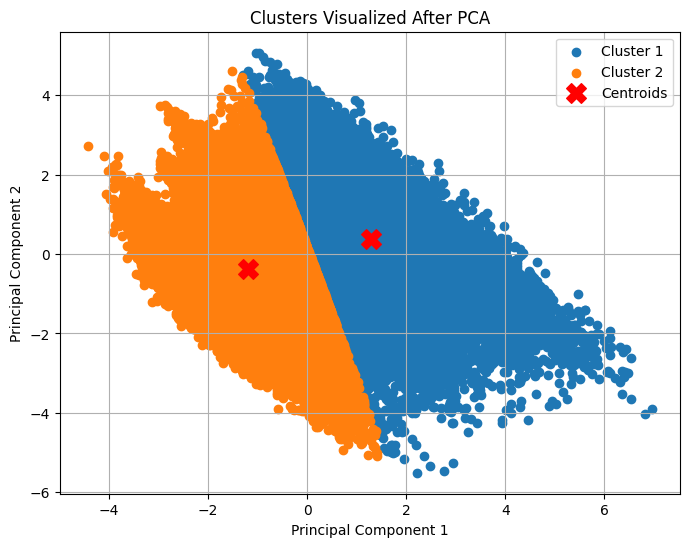

In [ ]:
from sklearn.decomposition import PCA
import numpy as np
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
# Applying PCA to reduce dimensions

kmeans = KMeans(n_clusters=2, random_state=42) 
kmeans.fit(X2d)
# labels = kmeans.labels_
labels=kmeans.predict(X2d)
# Visualising clusters for K-Means in 2D
plt.figure(figsize=(8, 6))

for i in range(kmeans.n_clusters):
    points = X2d[labels == i]  # Logical indexing works with NumPy arrays
    plt.scatter(points[:, 0], points[:, 1], label=f'Cluster {i + 1}')

plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], c='red', marker='X', s=200, label='Centroids')
plt.title('Clusters Visualized After PCA')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend()
plt.grid()
plt.show()
# Hint: Set n_components=2 for 2D visualisation or n_components=3 for 3D visualisation.
# plt.scatter()
# plt.show()

#### 3.3.4: Implement Random Hierarchical Clustering

In [ ]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
import numpy as np

df_sampled = resample(scaled_df, n_samples=20000, random_state=42)
data_pca=pca.fit_transform(df_sampled)
X2d = np.array(data_pca)
# Initialising and fiting hierarchical clustering
hierarchical = AgglomerativeClustering(n_clusters=2)
hierarchical_labels= hierarchical.fit_predict(X2d)

# Evaluating with Silhouette Score
hierarchical_silhouette =silhouette_score(X2d,hierarchical_labels) 
print(f"Hierarchical Clustering Silhouette Score: {hierarchical_silhouette}")

Hierarchical Clustering Silhouette Score: 0.33484215228322717


#### 3.3.5: Implement DBSCAN for Density-Based Clustering

In [ ]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
import numpy as np

# Initialising and fiting DBSCAN
dbscan = DBSCAN(eps=0.5,min_samples=10)
dbscan_labels = dbscan.fit_predict(scaled_df)

# Filtering noise points (labeled as -1)
core_samples_mask = dbscan_labels != -1
scaled_df_core = scaled_df[core_samples_mask]
labels_core = dbscan_labels[core_samples_mask]

# Evaluate with Silhouette Score (excluding noise)
if len(set(labels_core)) > 1:  # Silhouette Score is only valid with at least 2 clusters
    dbscan_silhouette = silhouette_score(scaled_df_core, labels_core)
    print(f"DBSCAN Clustering Silhouette Score (excluding noise): {dbscan_silhouette:.2f}")
else:
    print("Silhouette Score cannot be computed with less than 2 clusters (excluding noise).")

DBSCAN Clustering Silhouette Score (excluding noise): 0.31


#### 3.3.6: Evaluation and Model Comparison

In [166]:
# Summary of Silhouette Scores
results = {
    "Clustering Method": ["K-Means", "Hierarchical", "DBSCAN"],
    "Silhouette Score": [silhouette_avg, hierarchical_silhouette, dbscan_silhouette]
}

for method, score in zip(results["Clustering Method"], results["Silhouette Score"]):
    print(f"{method}: Silhouette Score = {score}")

K-Means: Silhouette Score = 0.1131434345461253
Hierarchical: Silhouette Score = 0.33484215228322717
DBSCAN: Silhouette Score = 0.31195866657427074


#### Expected Output for Model Comparison in 3.3.6:
| Clustering Method | Silhouette Score |
|     ---           |    --   |
| K-Means           |  0.113|
| Hierarchical      | 0.334 |
| DBSCAN            | 0.311 |

++++++++++
### **3.4 Feature Engineering and Feature Selection**
Select the most relevant features to improve model performance

#### 3.4.1: Feature Engineering

 In ### **Task 3.1: Implementing Regression Baseline** 12th cell

In [ ]:
# convert age column to numeric 
def convert_age_to_numeric(age_range):
    if isinstance(age_range, str):  # Check if the value is a string
        start, end = age_range.strip("[]()").split('-')
        start, end = int(start), int(end)
        return (start + end) / 2  # Calculate the average
    else:
        return None  # Handle non-string values (e.g., NaN)



data['age'] = data['age'].apply(convert_age_to_numeric)

# It might not work here or could produce an error because I cleaned my data in each section using different data names and x, y values.
# Please run it in Task 3.1, 12th cell. I have the code there, so you can verify that it is working.

#### 3.4.2: Generate Statistical Features
Calculate aggregate statistics such as mean, max, min, or standard deviation for features if relevant

###in Task 3.1, 6th cell

In [ ]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# Patient_num column
# data['patient_nbr'].value_counts()
data['visit']=data.groupby('patient_nbr')['patient_nbr'].transform('count')
data['visit'].describe()
data.plot.scatter(x='visit',y='time_in_hospital')

data['visit'].describe()


# It might not work here or could produce an error because I cleaned my data in each section using different data names and x, y values.
# Please run it in Task 3.1, 6th cell. I have the code there, so you can verify that it is working.

#### 3.4.3: Feature Transformation
Normalise or standardise features, especially for distance-based models like KNN or clustering

###in Task 3.1, 17th cell

In [ ]:

# scaling my data 
from sklearn.preprocessing import StandardScaler

df=pd.DataFrame(data)
numerical_data = df.select_dtypes(include=['int64','float64'])
scaler=StandardScaler()
scaled_data=scaler.fit_transform(numerical_data)
scaled_df=pd.DataFrame(scaled_data,columns=numerical_data.columns)

# It might not work here or could produce an error because I cleaned my data in each section using different data names and x, y values.
# Please run it in Task 3.1, 17th cell. I have the code there, so you can verify that it is working.

#### 3.4.4: Feature Selection
Use feature importance from tree-based models (Random Forest, Gradient Boosting) to select important features


In [173]:
scaled_df

,race,age,admission_type_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_inpatient,number_diagnoses,insulin,change,diabetesMed,readmitted,admission_source,discharge_disposition_numeric
0,0.401463,-3.824600,2.750800,-1.137649,-0.106517,-0.785398,-1.848268,-0.291461,-0.503276,-3.321596,-0.870219,-0.926591,-1.829868,-0.83688,-1.448033,3.505326
1,0.401463,-3.197277,-0.708461,-0.467653,0.808384,-0.785398,0.243390,-0.291461,-0.503276,0.815784,2.107113,1.079225,0.546488,0.62497,0.644047,-0.479838
2,-1.340842,-2.569954,-0.708461,-0.802651,-1.631351,2.145781,-0.371804,1.286748,0.288579,-0.735733,-0.870219,-0.926591,0.546488,-0.83688,0.644047,-0.479838
3,0.401463,-1.942632,-0.708461,-0.802651,0.045967,-0.199162,-0.002688,-0.291461,-0.503276,-0.218561,2.107113,1.079225,0.546488,-0.83688,0.644047,-0.479838
4,0.401463,-1.315309,-0.708461,-1.137649,0.401761,-0.785398,-0.986997,-0.291461,-0.503276,-1.252906,0.122225,1.079225,0.546488,-0.83688,0.644047,-0.479838
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
101761,-1.340842,0.566659,-0.708461,-0.467653,0.401761,-0.785398,-0.002688,-0.291461,-0.503276,0.815784,1.114669,1.079225,0.546488,0.62497,0.644047,0.516453
101762,-1.340842,1.193982,-0.708461,0.202343,-0.513139,0.973309,0.243390,-0.291461,0.288579,0.815784,0.122225,-0.926591,0.546488,-0.83688,-0.401993,0.516453
101763,0.401463,0.566659,-0.708461,-1.137649,0.503417,-0.785398,-0.863958,0.497643,-0.503276,2.884475,1.114669,1.079225,0.546488,-0.83688,0.644047,-0.479838
101764,0.401463,1.193982,-0.016609,1.877333,0.096794,0.387074,0.612506,-0.291461,0.288579,0.815784,2.107113,1.079225,0.546488,-0.83688,0.644047,0.516453


Index(['race', 'age', 'admission_type_id', 'num_lab_procedures',
       'num_procedures', 'num_medications', 'number_outpatient',
       'number_inpatient', 'number_diagnoses', 'insulin', 'change',
       'diabetesMed', 'readmitted', 'admission_source',
       'discharge_disposition_numeric'],
      dtype='object')
[4.72098692e-04 6.03987675e-03 7.40524469e-03 1.93935428e-01
 2.08782109e-02 6.71864552e-01 5.10036870e-05 4.30070248e-03
 4.41254238e-03 4.01916342e-04 0.00000000e+00 0.00000000e+00
 4.05613545e-05 1.32530131e-02 7.69448497e-02]


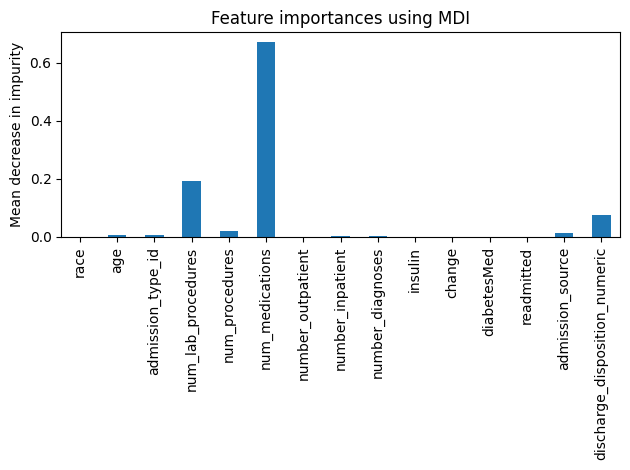

In [ ]:
from sklearn.ensemble import RandomForestRegressor
import matplotlib.pyplot as plt

# Fit Random Forest model
rfs=RandomForestRegressor(n_estimators=10,max_depth=6)
rfs.fit(scaled_df.drop('time_in_hospital',axis=1),scaled_df['time_in_hospital'])
# Get feature importance
print(scaled_df.drop('time_in_hospital',axis=1).columns)
importances = rfs.feature_importances_
print(importances)


# Plot feature importance
import pandas as pd

forest_importances = pd.Series(importances, index=scaled_df.drop('time_in_hospital',axis=1).columns)

fig, ax = plt.subplots()
forest_importances.plot.bar( ax=ax)
ax.set_title("Feature importances using MDI")
ax.set_ylabel("Mean decrease in impurity")
fig.tight_layout()

#### 3.4.5: Model Evaluation After Feature Selection
- After feature engineering and selection, evaluate your model with the new set of features.
- Apply cross-validation to measure the model's performance with the refined feature set

In [168]:

from sklearn.model_selection import cross_val_score

# Fit model on selected features
cv_score=cross_val_score(rfs,scaled_df[['num_medications','num_lab_procedures','discharge_disposition_numeric']],scaled_df['time_in_hospital'],cv=5,scoring='neg_mean_squared_error')
mean_cv_score = - cv_score.mean()

print("Cross-validated accuracy after feature selection:",-cv_score)
print("Mean CV MSE Score:", mean_cv_score)

Cross-validated accuracy after feature selection: [0.83329558 0.79111365 0.74084288 0.66050396 0.63230439]
Mean CV MSE Score: 0.7316120918300056


+++++++++
### **Task 3.5: Hyperparameter Tuning**
Improve the quality of your implementations


#### 3.5.1: GridSearchCV for Systematic Hyperparameter Tuning
- Define Hyperparameter Grid for Different Models
- Define grids of hyperparameters for models such as Logistic Regression (for classification) and K-Means (for clustering).

In [54]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV,cross_val_score
from sklearn.metrics import accuracy_score,f1_score
from sklearn.model_selection import train_test_split


x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

# Create a DecisionTreeRegressor
dt = DecisionTreeClassifier(random_state=42)

# Define the parameter grid
param_grid = {
    'criterion': ['gini', 'entropy','log_loss'],  # Splitting criteria
    'max_depth': [None,5,10,15],  # Maximum depth of the tree
    'min_samples_split': [2,5,8,10,12],  # Minimum samples to split a node
    'min_samples_leaf': [ 1,2] # Minimum samples in a leaf
    # 'max_features': [None, 'sqrt', 'log2'] # Number of features to consider

}

# Use GridSearchCV to find the best parameters accuracy
grid_search = GridSearchCV(estimator=dt, param_grid=param_grid, scoring='accuracy', cv=5, verbose=1, n_jobs=-1)



# It might not work here or could produce an error because I cleaned my data in each section using different data names and x, y values.
# Please run it in Task 3.2.3, second cell. I have the code there, so you can verify that it is working.

#### 3.5.2 Apply GridSearchCV with Cross-Validation
- Use GridSearchCV with cross-validation to perform hyperparameter tuning on both models.

In [ ]:
# Split the data
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

# Create a LogisticRegression instance
log_reg = LogisticRegression(random_state=42, max_iter=500)

# Define the parameter grid
param_grid = {
    'penalty': ['l1'],  # Regularization types
    'C': [ 0.01, 0.1, 1, 10],         # Inverse regularization strength
    'solver': [ 'liblinear','saga'],  # Solvers
    'max_iter': [500,1000]              # Only relevant for 'elasticnet'
}

# GridSearchCV to find the best parameters for accuracy
grid_search = GridSearchCV(estimator=log_reg, param_grid=param_grid, scoring='accuracy', cv=3, verbose=1, n_jobs=4)
grid_search.fit(x_train, y_train)

# GridSearchCV to find the best parameters for f1-score
grid_search_f1 = GridSearchCV(estimator=log_reg, param_grid=param_grid, scoring='f1', cv=3, verbose=1, n_jobs=4)
grid_search_f1.fit(x_train, y_train)

# Evaluate the best models on the test set
best_model_accuracy = grid_search.best_estimator_
y_pred_accuracy = best_model_accuracy.predict(x_test)
best_model_f1 = grid_search_f1.best_estimator_
y_pred_f1 = best_model_f1.predict(x_test)

# Calculate and print metrics
accuracy = accuracy_score(y_test, y_pred_accuracy)
f1 = f1_score(y_test, y_pred_f1)
print("Test Set Accuracy:", accuracy)
print("Test Set F1 Score:", f1)


# It might not work here or could produce an error because I cleaned my data in each section using different data names and x, y values.
# Please run it in Task 3.2.3, second cell. I have the code there, so you can verify that it is working.



In [ ]:
from sklearn.cluster import KMeans
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.metrics import make_scorer, silhouette_score,rand_score
import numpy as np
import pandas as pd



kmeans_param_grid = {
    'n_clusters': [2, 3, 4, 5],  # Number of clusters
      'init': ['k-means++', 'random'],  # Initialization method
    #  'n_init': [10,20],  # Number of initializations
    #  'max_iter': [300,500]  # Maximum iterations
}

# silhouette_scorer = make_scorer(silhouette_score, greater_is_better=True)

def silhouette_scorer_custom(estimator, scaled_df):
    labels = estimator.fit_predict(scaled_df)
    score = silhouette_score(scaled_df, labels)
    return score

kmeans = KMeans(random_state=42)
kmeans_grid_search = GridSearchCV(estimator=kmeans, param_grid=kmeans_param_grid, scoring=silhouette_scorer_custom, cv=3)
kmeans_grid_search.fit(scaled_df)


# It might not work here or could produce an error because I cleaned my data in each section using different data names and x, y values.
# Please run it in Task 3.3.2, first cell. I have the code there, so you can verify that it is working.

#### 3.5.3: Nested Cross-Validation to Validate Stability of Hyperparameters

In [ ]:
from sklearn.model_selection import cross_val_score

# Logistic Regression Nested Cross-Validation
nested_cv_score_logistic = cross_val_score()
print("Nested CV Accuracy for Logistic Regression:")



from sklearn.model_selection import StratifiedKFold

# Outer cross-validation for model evaluation
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Inner cross-validation for hyperparameter tuning
inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)


# GridSearchCV for hyperparameter tuning
grid_search = GridSearchCV(estimator=dt, param_grid=param_grid, scoring='accuracy', cv=inner_cv, n_jobs=-1)

# Perform nested cross-validation
nested_scores = cross_val_score(grid_search, x, y, scoring='accuracy', cv=outer_cv)

# Print results
print("Nested CV Accuracy Scores:", nested_scores)
print("Mean Nested CV Accuracy:", nested_scores.mean())

# It might not work here or could produce an error because I cleaned my data in each section using different data names and x, y values.
# Please run it in Task 3.2.3, third cell. I have the code there, so you can verify that it is working.

#### 3.5.4: Evaluate Tuned Models with Multiple Metrics
- Evaluate the tuned Logistic Regression model on both training and test sets.
- Use multiple metrics for classification (accuracy, F1-score) and clustering (silhouette score, Calinski-Harabasz).

In [ ]:
from sklearn.metrics import accuracy_score, f1_score, silhouette_score, calinski_harabasz_score

# Logistic Regression evaluation
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV,cross_val_score
from sklearn.metrics import accuracy_score,f1_score
from sklearn.model_selection import train_test_split


x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

# Create a DecisionTreeRegressor
dt = DecisionTreeClassifier(random_state=42)

# Define the parameter grid
param_grid = {
    'criterion': ['gini', 'entropy','log_loss'],  # Splitting criteria
    'max_depth': [None,5,10,15],  # Maximum depth of the tree
    'min_samples_split': [2,5,8,10,12],  # Minimum samples to split a node
    'min_samples_leaf': [ 1,2] # Minimum samples in a leaf
    # 'max_features': [None, 'sqrt', 'log2'] # Number of features to consider

}

# Use GridSearchCV to find the best parameters accuracy
grid_search = GridSearchCV(estimator=dt, param_grid=param_grid, scoring='accuracy', cv=5, verbose=1, n_jobs=-1)
grid_search.fit(x_train, y_train)

# Use GridSearchCV to find the best parameters f1
grid_search_f1 = GridSearchCV(estimator=dt, param_grid=param_grid, scoring='f1', cv=5, verbose=1, n_jobs=-1)
grid_search_f1.fit(x_train, y_train)



# Evaluate the best model on the test set
best_model = grid_search.best_estimator_
y_pred = best_model.predict(x_test)
best_model_f1=grid_search_f1.best_estimator_
y_pred_1 = best_model_f1.predict(x_test)
accuracy= accuracy_score(y_test,y_pred)
f1=f1_score(y_test,y_pred_1)
print("Test Set Accuracy:", accuracy)
print("Test Set f1:", f1)

# KMeans evaluation
from sklearn.cluster import KMeans
from sklearn.model_selection import GridSearchCV, 
from sklearn.metrics import  silhouette_score,calinski_harabasz_score
import numpy as np
import pandas as pd



kmeans_param_grid = {
    'n_clusters': [2, 3, 4, 5],  # Number of clusters
      'init': ['k-means++', 'random'],  # Initialization method
    #  'n_init': [10,20],  # Number of initializations
    #  'max_iter': [300,500]  # Maximum iterations
}

# silhouette_scorer = make_scorer(silhouette_score, greater_is_better=True)

def silhouette_scorer_custom(estimator, scaled_df):
    labels = estimator.fit_predict(scaled_df)
    score = silhouette_score(scaled_df, labels)
    return score

kmeans = KMeans(random_state=42)
kmeans_grid_search = GridSearchCV(estimator=kmeans, param_grid=kmeans_param_grid, scoring=silhouette_scorer_custom, cv=3)
kmeans_grid_search.fit(scaled_df)

  


# Print best parameters and cross-validation silhouette score
print("KMeans - Best Parameters:", kmeans_grid_search.best_params_)
print("KMeans - Best CV Silhouette Score:", kmeans_grid_search.best_score_)



# Custom scorer using calinski_harabasz_score
def calinski_harabasz_scorer(estimator, scaled_df):
    # Fit the clustering model and predict cluster labels
    labels = estimator.fit_predict(scaled_df)
    # Calculate Calinski-Harabasz Score
    return calinski_harabasz_score(scaled_df, labels)



# Define a parameter grid for KMeans
param_grid = {
    'n_clusters': [2, 3, 4, 5, 6],  # Example: Testing different cluster numbers
    'init': ['k-means++', 'random'],
    # 'max_iter': [100, 300, 500]
}

# Initialize the clustering algorithm (e.g., KMeans)
kmeans = KMeans(random_state=42)

# Set up GridSearchCV
grid = GridSearchCV(estimator=kmeans, param_grid=param_grid, scoring=calinski_harabasz_scorer,n_jobs=-1, cv=3)

# Fit GridSearchCV on your dataset
grid.fit(scaled_df)  # X is your feature matrix

# Best parameters and score
print("Best Parameters:", grid.best_params_)
print("Best Calinski-Harabasz Score:", grid.best_score_)



# It might not work here or could produce an error because I cleaned my data in each section using different data names and x, y values.
# Please run it in Task 3.3.2, first and second cell. I have the code there, so you can verify that it is working.


+++++++++
### **Task 3.6: Model Selection**
- Compare and evaluate the implemented models and select the best ones.

#### 3.6.1: Compare and Choose the Best Model
- Compare the models using evaluation metrics (e.g., MSE for regression, F1-score for classification, Silhouette Score for clustering).
- Summarise the performance metrics of each model in a table and choose the model with the best performance for each task.

In [149]:
import pandas as pd

# Sample model comparison
results = {
    "Model": ["Linear Regression", "Random Forest Regression", "KMeans",'RandomForestClassifier'],
    "MAE": [mae, mae_r, "N/A","N/A"],
    "MSE": [mse, mse_r, "N/A","N/A"],
    "Silhouette Score": ["N/A", "N/A", silhouette_avg,"N/A"],
    "F1": ["N/A", "N/A", "N/A",f1_r]
}

results_df = pd.DataFrame(results)
print(results_df)

                      Model       MAE       MSE Silhouette Score       F1
0         Linear Regression  1.906336  6.261203              N/A      N/A
1  Random Forest Regression   1.95426  6.696863              N/A      N/A
2                    KMeans       N/A       N/A         0.113148      N/A
3    RandomForestClassifier       N/A       N/A              N/A  0.55857


#### 3.6.2: Finalise and Save the Best Model
- Once the best model is identified, retrain it on the full dataset and save it using joblib for future use.

In [ ]:
import joblib

# Save the best model
joblib.dump(grid_search.best_estimator_, "best_model.pkl")



____________
## *Task 4: Mathematics for Machine Learning

#### 4.1: Implementing Linear Regression with Numpy from Scratch

- Add all links to your Jupyter notebook files `LinearRegression.ipynb` here!

#### 4.2: Implement Logistic Regression with Numpy from Scratch

- Add all links to your Jupyter notebook files `LogisticRegression.ipynb` here!

____________
## *Task 5: Final Report for Your Creative Brief Project
- Add a link to your `FinalReport_<your_name>_<studentnumber>.pdf` here!